# Detection of Fraudulent Financial Transactions
## Using Data Analytics and Machine Learning

**Student:** Yaswanth Sai Tummala
**Student ID:** S3423122 
**Module:** CIS4055 - Computing Masters Project
**University:** Teesside University
**Dataset:** Financial Transactions Dataset (Kaggle) https://www.kaggle.com/datasets/aryan208/financial-transactions-dataset-for-fraud-detection/data

---

### Project Overview
This notebook covers the complete data science pipeline for fraud detection:
1. Data loading and inspection
2. Data cleaning and preprocessing
3. Exploratory Data Analysis (EDA)
4. Feature engineering
5. Machine learning model training and evaluation
6. Model comparison and final conclusions


## Section 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine learning tools
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, precision_recall_curve, ConfusionMatrixDisplay
)

# For handling imbalanced dataset (fraud is rare - only ~1%)
from imblearn.over_sampling import SMOTE

# XGBoost is a powerful gradient boosting model
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    print("XGBoost not installed. Run: pip install xgboost")
    XGBOOST_AVAILABLE = False

# Make matplotlib plots look nice
plt.rcParams['figure.facecolor'] = '#f8f9fa'
plt.rcParams['axes.facecolor']   = '#ffffff'
plt.rcParams['axes.spines.top']    = False
plt.rcParams['axes.spines.right']  = False
plt.rcParams['font.family']        = 'DejaVu Sans'
sns.set_palette("husl")

print("All libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"Numpy version: {np.__version__}")


XGBoost not installed. Run: pip install xgboost
All libraries imported successfully!
Pandas version: 2.3.3
Numpy version: 2.3.5


In [2]:
pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   --- ------------------------------------ 8.9/101.7 MB 38.1 MB/s eta 0:00:03
   ------ --------------------------------- 16.8/101.7 MB 38.2 MB/s eta 0:00:03
   ---------- ----------------------------- 26.7/101.7 MB 39.8 MB/s eta 0:00:02
   ---------------- ----------------------- 41.7/101.7 MB 47.0 MB/s eta 0:00:02
   ---------------------- ----------------- 56.6/101.7 MB 51.2 MB/s eta 0:00:01
   ---------------------------- ----------- 71.3/101.7 MB 53.8 MB/s eta 0:00:01
   -------------------------------- ------- 82.8/101.7 MB 53.8 MB/s eta 0:00:01
   ------------------------------------- -- 94.9/101.7 MB 53.9 MB/s eta 0:00:01
   --------------------------------------  101.4/101.7 MB 53.8 MB/s eta 0:00:01
   --------------------------------------  101.4/101.7 MB 53.8 MB/s eta 0:00:01
   --------------------------------------  101.4/101.7 MB 5

## Section 2: Load the Dataset

In [3]:
CSV_PATH = r"C:\Users\yaswa\OneDrive\Desktop\Yashwanth Dissertation\Dataset\financial_fraud_detection_dataset.csv"


SAMPLE_SIZE = 200_000

print(f"Loading {SAMPLE_SIZE:,} rows from dataset...")
df = pd.read_csv(CSV_PATH, nrows=SAMPLE_SIZE)

print(f"\nDataset loaded successfully!")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"\nColumn names:")
for col in df.columns:
    print(f"  - {col}")

Loading 200,000 rows from dataset...

Dataset loaded successfully!
Shape: 200,000 rows × 18 columns

Column names:
  - transaction_id
  - timestamp
  - sender_account
  - receiver_account
  - amount
  - transaction_type
  - merchant_category
  - location
  - device_used
  - is_fraud
  - fraud_type
  - time_since_last_transaction
  - spending_deviation_score
  - velocity_score
  - geo_anomaly_score
  - payment_channel
  - ip_address
  - device_hash


### # Look at the first few rows to understand the data structure

In [4]:
print("First 5 rows of the dataset:")
df.head()


First 5 rows of the dataset:


,transaction_id,timestamp,sender_account,receiver_account,amount,transaction_type,merchant_category,location,device_used,is_fraud,fraud_type,time_since_last_transaction,spending_deviation_score,velocity_score,geo_anomaly_score,payment_channel,ip_address,device_hash
0,T100000,2023-08-22T09:22:43.516168,ACC877572,ACC388389,343.78,withdrawal,utilities,Tokyo,mobile,False,NaN,NaN,-0.21,3,0.22,card,13.101.214.112,D8536477
1,T100001,2023-08-04T01:58:02.606711,ACC895667,ACC944962,419.65,withdrawal,online,Toronto,atm,False,NaN,NaN,-0.14,7,0.96,ACH,172.52.47.194,D2622631
2,T100002,2023-05-12T11:39:33.742963,ACC733052,ACC377370,2773.86,deposit,other,London,pos,False,NaN,NaN,-1.78,20,0.89,card,185.98.35.23,D4823498
3,T100003,2023-10-10T06:04:43.195112,ACC996865,ACC344098,1666.22,deposit,online,Sydney,pos,False,NaN,NaN,-0.60,6,0.37,wire_transfer,107.136.36.87,D9961380
4,T100004,2023-09-24T08:09:02.700162,ACC584714,ACC497887,24.43,transfer,utilities,Toronto,mobile,False,NaN,NaN,0.79,13,0.27,ACH,108.161.108.255,D7637601


In [5]:
# ---------------------------------------------------------------
# Check data types and memory usage
# ---------------------------------------------------------------

print("Data types for each column:")
print(df.dtypes)
print(f"\nTotal memory used: {df.memory_usage(deep=True).sum() / 1024 / 1024:.1f} MB")

Data types for each column:
transaction_id                  object
timestamp                       object
sender_account                  object
receiver_account                object
amount                         float64
transaction_type                object
merchant_category               object
location                        object
device_used                     object
is_fraud                          bool
fraud_type                      object
time_since_last_transaction    float64
spending_deviation_score       float64
velocity_score                   int64
geo_anomaly_score              float64
payment_channel                 object
ip_address                      object
device_hash                     object
dtype: object

Total memory used: 136.6 MB


In [6]:
# ---------------------------------------------------------------
# Basic statistics for all numeric columns
# This shows min, max, mean, and standard deviation
# ---------------------------------------------------------------

print("Statistical summary of numeric columns:")
df.describe().round(3)


Statistical summary of numeric columns:


,amount,time_since_last_transaction,spending_deviation_score,velocity_score,geo_anomaly_score
count,200000.000,20431.000,200000.000,200000.000,200000.000
mean,358.417,24.997,0.002,10.483,0.500
std,469.207,3572.268,0.999,5.769,0.289
min,0.010,-8680.498,-4.630,1.000,0.000
25%,26.658,-2523.454,-0.680,5.000,0.250
50%,138.390,35.129,0.000,10.000,0.500
75%,503.365,2596.682,0.680,15.000,0.750
max,2833.230,8706.600,4.250,20.000,1.000


## Section 3: Data Cleaning and Preprocessing

In [7]:
# ---------------------------------------------------------------
# Step 3.1: Check for missing values in each column
# Missing values can break machine learning models
# ---------------------------------------------------------------

missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})

print("Missing values report:")
print(missing_df[missing_df['Missing Count'] > 0])
print(f"\nTotal columns with missing values: {(missing > 0).sum()}")


Missing values report:
                             Missing Count  Missing %
fraud_type                          199138      99.57
time_since_last_transaction         179569      89.78

Total columns with missing values: 2


In [8]:
# ---------------------------------------------------------------
# Step 3.2: Fix missing values
# - fraud_type is missing for non-fraud rows → fill with 'No Fraud'
# - Score columns fill with median (middle value)
# ---------------------------------------------------------------

# Fill fraud_type - it's blank for non-fraud transactions, that is correct
df['fraud_type'] = df['fraud_type'].fillna('No Fraud')

# Fill missing score columns with median values
score_cols = ['time_since_last_transaction', 'spending_deviation_score', 'geo_anomaly_score']
for col in score_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)
    print(f"Filled '{col}' missing values with median = {median_val:.4f}")

print("\nAfter cleaning - missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("No missing values remain!" if df.isnull().sum().sum() == 0 else "")


Filled 'time_since_last_transaction' missing values with median = 35.1295
Filled 'spending_deviation_score' missing values with median = 0.0000
Filled 'geo_anomaly_score' missing values with median = 0.5000

After cleaning - missing values:
Series([], dtype: int64)
No missing values remain!


In [9]:
# ---------------------------------------------------------------
# Step 3.3: Fix data types
# Convert timestamp string to actual datetime object
# Convert is_fraud from True/False to 1/0 (machine learning needs numbers)
# ---------------------------------------------------------------

# Convert timestamp to datetime (Python can then extract hour, day, month etc.)
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Convert boolean is_fraud to integer (True→1, False→0)
df['is_fraud'] = df['is_fraud'].astype(int)

# Extract useful time features from the timestamp
df['hour']        = df['timestamp'].dt.hour           # 0-23
df['day_of_week'] = df['timestamp'].dt.dayofweek      # 0=Monday, 6=Sunday
df['month']       = df['timestamp'].dt.month          # 1-12
df['day_name']    = df['timestamp'].dt.day_name()     # Monday, Tuesday...
df['month_name']  = df['timestamp'].dt.month_name()   # January, February...
df['is_weekend']  = (df['day_of_week'] >= 5).astype(int)  # 1 if weekend

print("Data types after conversion:")
print(df[['timestamp','is_fraud','hour','day_of_week','month']].dtypes)
print("\nNew time columns added successfully!")


Data types after conversion:
timestamp      datetime64[ns]
is_fraud                int64
hour                    int32
day_of_week             int32
month                   int32
dtype: object

New time columns added successfully!


In [10]:
# ---------------------------------------------------------------
# Step 3.4: Check for duplicate rows
# Duplicate transaction_ids would be a data quality problem
# ---------------------------------------------------------------

total_rows      = len(df)
duplicate_rows  = df.duplicated(subset=['transaction_id']).sum()

print(f"Total rows         : {total_rows:,}")
print(f"Duplicate rows     : {duplicate_rows:,}")
print(f"Unique transactions: {total_rows - duplicate_rows:,}")

# Remove duplicates if any exist
if duplicate_rows > 0:
    df = df.drop_duplicates(subset=['transaction_id'])
    print(f"Removed {duplicate_rows} duplicate rows.")
else:
    print("No duplicates found - data is clean!")


Total rows         : 200,000
Duplicate rows     : 0
Unique transactions: 200,000
No duplicates found - data is clean!


In [11]:
# ---------------------------------------------------------------
# Step 3.5: Check the target variable
# is_fraud = 1 → fraudulent transaction
# is_fraud = 0 → normal/legitimate transaction
# This tells us how imbalanced the dataset is
# ---------------------------------------------------------------

fraud_counts = df['is_fraud'].value_counts()
fraud_pct    = df['is_fraud'].value_counts(normalize=True) * 100

print("Target variable distribution:")
print(f"  Legitimate (0): {fraud_counts[0]:,} rows  ({fraud_pct[0]:.2f}%)")
print(f"  Fraud      (1): {fraud_counts[1]:,} rows  ({fraud_pct[1]:.2f}%)")
print(f"\nImbalance ratio: 1 fraud for every {int(fraud_counts[0]/fraud_counts[1])} legitimate transactions")
print("This means we have a heavily imbalanced dataset - we will fix this with SMOTE later.")


Target variable distribution:
  Legitimate (0): 199,138 rows  (99.57%)
  Fraud      (1): 862 rows  (0.43%)

Imbalance ratio: 1 fraud for every 231 legitimate transactions
This means we have a heavily imbalanced dataset - we will fix this with SMOTE later.


## Section 4: Feature Engineering

In [12]:
# ---------------------------------------------------------------
# Feature Engineering creates new columns (features) that help
# the machine learning model identify fraud better
# These features are based on the research question in my initial proposal
# ---------------------------------------------------------------

# Feature 1: Is this a large transaction?
# (above 75th percentile = unusual/high amount)
amount_75th = df['amount'].quantile(0.75)
df['is_high_amount'] = (df['amount'] > amount_75th).astype(int)
print(f"Feature 1 - is_high_amount: Threshold = ${amount_75th:.2f}")

# Feature 2: Is the velocity score very high?
# High velocity = many transactions in a short time = suspicious
velocity_75th = df['velocity_score'].quantile(0.75)
df['is_high_velocity'] = (df['velocity_score'] > velocity_75th).astype(int)
print(f"Feature 2 - is_high_velocity: Threshold = {velocity_75th}")

# Feature 3: Is the spending deviation very high?
# High deviation means spending way more than usual
deviation_75th = df['spending_deviation_score'].quantile(0.75)
df['is_high_deviation'] = (df['spending_deviation_score'] > deviation_75th).astype(int)
print(f"Feature 3 - is_high_deviation: Threshold = {deviation_75th:.4f}")

# Feature 4: Is geo anomaly score high? (unusual location)
geo_75th = df['geo_anomaly_score'].quantile(0.75)
df['is_geo_anomaly'] = (df['geo_anomaly_score'] > geo_75th).astype(int)
print(f"Feature 4 - is_geo_anomaly: Threshold = {geo_75th:.4f}")

# Feature 5: Risk combination score
# Add up all the risk flags to get an overall risk number (0-4)
df['risk_flag_sum'] = (df['is_high_amount'] + df['is_high_velocity'] +
                       df['is_high_deviation'] + df['is_geo_anomaly'])
print(f"Feature 5 - risk_flag_sum: Combined risk (0=safe, 4=very risky)")

# Feature 6: Is the transaction during night hours? (12am - 6am = unusual)
df['is_night_txn'] = ((df['hour'] >= 0) & (df['hour'] < 6)).astype(int)
print(f"Feature 6 - is_night_txn: 1 if between midnight and 6am")

# Feature 7: Time since last transaction bucket
# Very quick follow-up transactions can be suspicious
df['is_quick_followup'] = (df['time_since_last_transaction'] < 1.0).astype(int)
print(f"Feature 7 - is_quick_followup: 1 if next transaction within 1 hour")

print("\nAll 7 new features created!")
print(f"Dataset now has {df.shape[1]} columns (was 18)")


Feature 1 - is_high_amount: Threshold = $503.37
Feature 2 - is_high_velocity: Threshold = 15.0
Feature 3 - is_high_deviation: Threshold = 0.6800
Feature 4 - is_geo_anomaly: Threshold = 0.7500
Feature 5 - risk_flag_sum: Combined risk (0=safe, 4=very risky)
Feature 6 - is_night_txn: 1 if between midnight and 6am
Feature 7 - is_quick_followup: 1 if next transaction within 1 hour

All 7 new features created!
Dataset now has 31 columns (was 18)


In [13]:
# ---------------------------------------------------------------
# Check how our new features relate to fraud
# This confirms they are useful for detection
# ---------------------------------------------------------------

new_features = ['is_high_amount','is_high_velocity','is_high_deviation',
                'is_geo_anomaly','is_night_txn','is_quick_followup','risk_flag_sum']

print("Fraud rate by new feature (0=not triggered, 1=triggered):")
print("-" * 60)
for feat in new_features:
    rates = df.groupby(feat)['is_fraud'].mean() * 100
    print(f"{feat}:")
    for k, v in rates.items():
        print(f"   {k} → {v:.3f}% fraud rate")
    print()


Fraud rate by new feature (0=not triggered, 1=triggered):
------------------------------------------------------------
is_high_amount:
   0 → 0.419% fraud rate
   1 → 0.468% fraud rate

is_high_velocity:
   0 → 0.435% fraud rate
   1 → 0.420% fraud rate

is_high_deviation:
   0 → 0.439% fraud rate
   1 → 0.406% fraud rate

is_geo_anomaly:
   0 → 0.425% fraud rate
   1 → 0.449% fraud rate

is_night_txn:
   0 → 0.415% fraud rate
   1 → 0.479% fraud rate

is_quick_followup:
   0 → 0.211% fraud rate
   1 → 4.559% fraud rate

risk_flag_sum:
   0 → 0.414% fraud rate
   1 → 0.440% fraud rate
   2 → 0.447% fraud rate
   3 → 0.401% fraud rate
   4 → 0.291% fraud rate



## Section 5: Exploratory Data Analysis (EDA)

> This section contains **EDA visualisations** showing fraud patterns across different dimensions.
> Each graph has a clear title and is designed to be easy to understand.


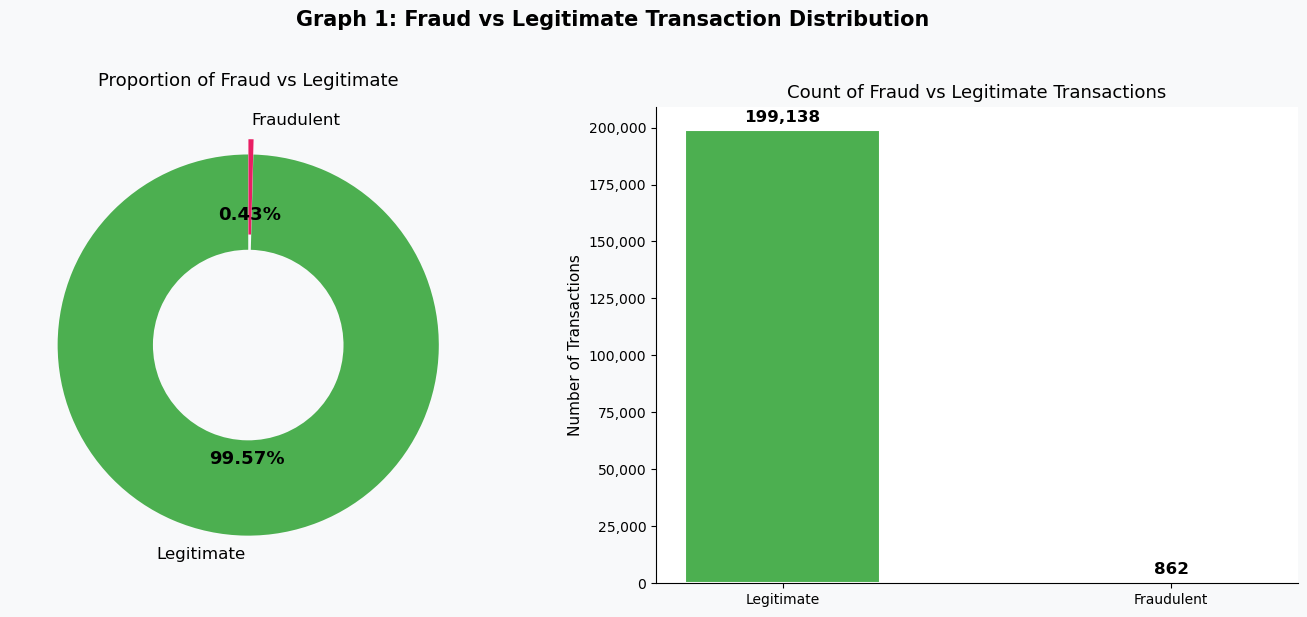

Graph 1 saved.


In [14]:
# ---------------------------------------------------------------
# GRAPH 1: Fraud vs Legitimate Distribution (Donut Chart)
# Shows what proportion of transactions are fraudulent
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Graph 1: Fraud vs Legitimate Transaction Distribution',
             fontsize=15, fontweight='bold', y=1.02)

# Left: Donut chart
counts = df['is_fraud'].value_counts()
labels = ['Legitimate', 'Fraudulent']
colors = ['#4CAF50', '#E91E63']
explode = (0, 0.08)

wedges, texts, autotexts = axes[0].pie(
    counts, labels=labels, colors=colors,
    autopct='%1.2f%%', startangle=90,
    explode=explode, wedgeprops=dict(width=0.5),
    textprops={'fontsize': 12}
)
for at in autotexts:
    at.set_fontweight('bold')
    at.set_fontsize(13)
axes[0].set_title('Proportion of Fraud vs Legitimate', fontsize=13, pad=15)

# Right: Bar chart with counts
bars = axes[1].bar(labels, counts.values, color=colors, edgecolor='white',
                   linewidth=1.5, width=0.5)
axes[1].set_title('Count of Fraud vs Legitimate Transactions', fontsize=13)
axes[1].set_ylabel('Number of Transactions', fontsize=11)
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'))
for bar, val in zip(bars, counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + max(counts.values)*0.01,
                 f'{val:,}', ha='center', va='bottom',
                 fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig('graph01_fraud_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 1 saved.")


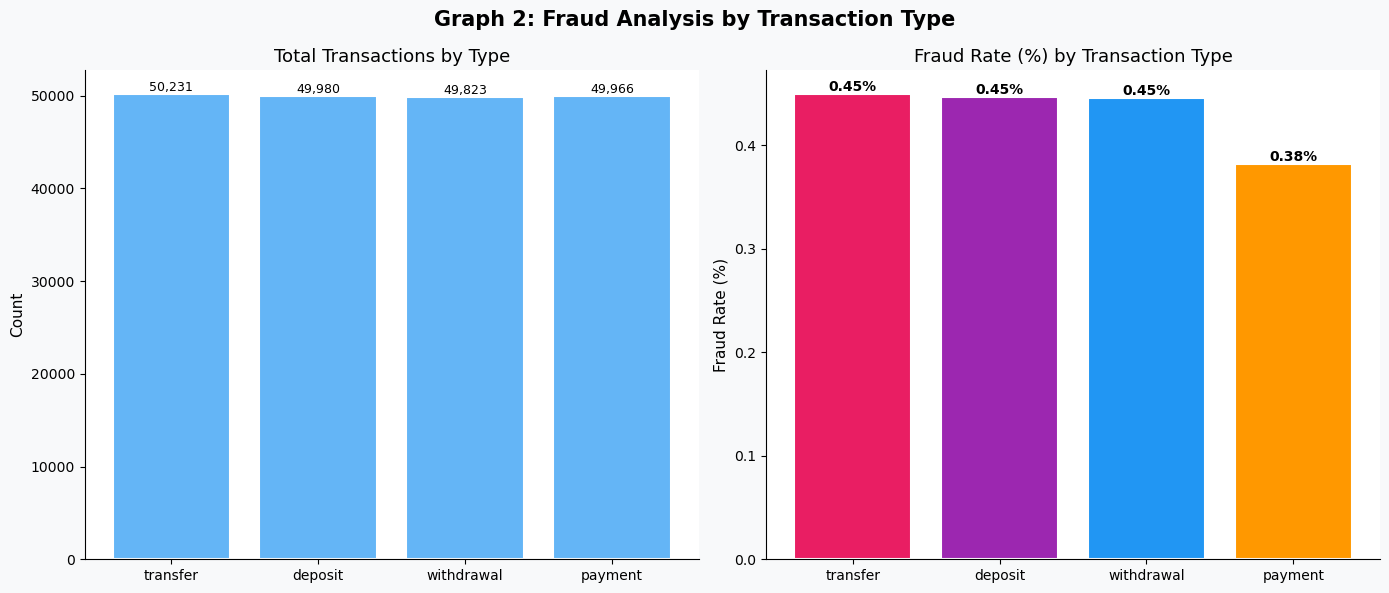

Graph 2 saved.


In [15]:
# ---------------------------------------------------------------
# GRAPH 2: Fraud by Transaction Type
# Which type of transaction (withdrawal, deposit, etc.) has most fraud?
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Graph 2: Fraud Analysis by Transaction Type',
             fontsize=15, fontweight='bold')

# Prepare data
type_fraud = df.groupby('transaction_type').agg(
    total=('is_fraud','count'),
    fraud=('is_fraud','sum')
).reset_index()
type_fraud['fraud_rate'] = type_fraud['fraud'] / type_fraud['total'] * 100
type_fraud = type_fraud.sort_values('fraud', ascending=False)

colors = ['#E91E63','#9C27B0','#2196F3','#FF9800']

# Left: Total count
bars = axes[0].bar(type_fraud['transaction_type'], type_fraud['total'],
                   color='#64B5F6', edgecolor='white', linewidth=1.5)
axes[0].set_title('Total Transactions by Type', fontsize=13)
axes[0].set_ylabel('Count', fontsize=11)
for bar, val in zip(bars, type_fraud['total']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f'{val:,}', ha='center', va='bottom', fontsize=9)

# Right: Fraud rate
bars2 = axes[1].bar(type_fraud['transaction_type'], type_fraud['fraud_rate'],
                    color=colors[:len(type_fraud)], edgecolor='white', linewidth=1.5)
axes[1].set_title('Fraud Rate (%) by Transaction Type', fontsize=13)
axes[1].set_ylabel('Fraud Rate (%)', fontsize=11)
for bar, val in zip(bars2, type_fraud['fraud_rate']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f'{val:.2f}%', ha='center', va='bottom',
                 fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('graph02_transaction_type.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 2 saved.")


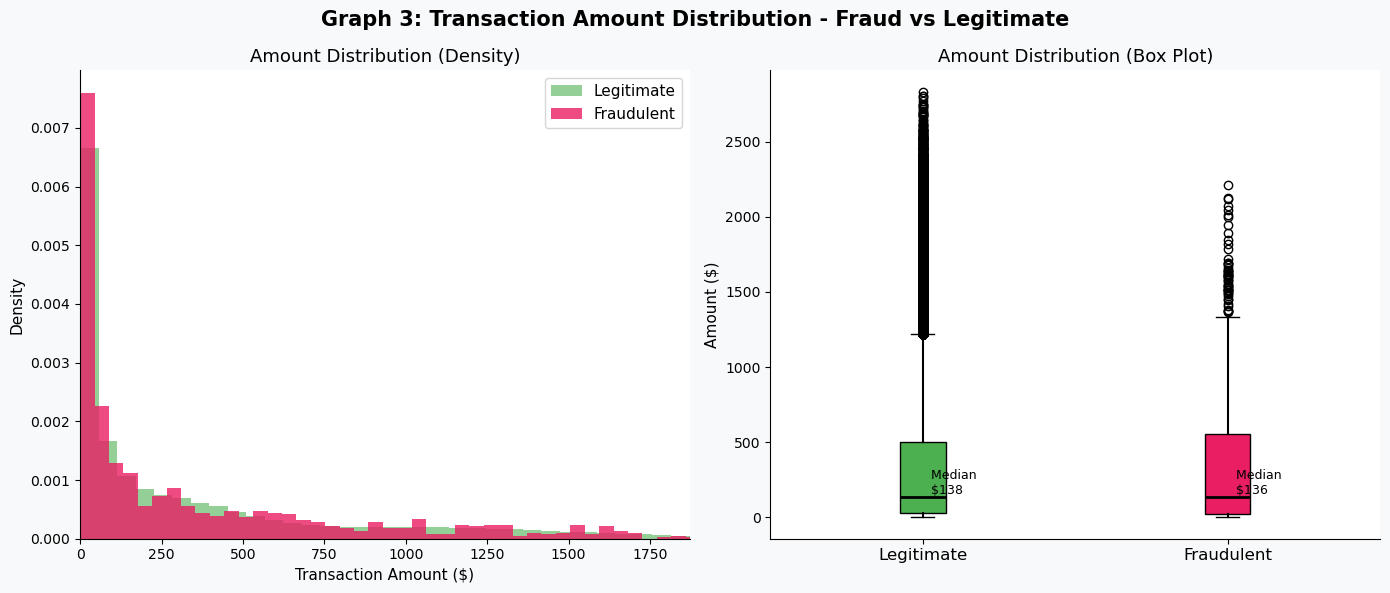

Graph 3 saved.


In [16]:
# ---------------------------------------------------------------
# GRAPH 3: Transaction Amount Distribution (Fraud vs Legitimate)
# Fraudulent transactions - do they involve larger or smaller amounts?
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Graph 3: Transaction Amount Distribution - Fraud vs Legitimate',
             fontsize=15, fontweight='bold')

fraud_amounts     = df[df['is_fraud']==1]['amount']
legit_amounts     = df[df['is_fraud']==0]['amount']

# Left: Overlapping histogram (log scale because amounts vary a lot)
axes[0].hist(legit_amounts, bins=50, alpha=0.6, color='#4CAF50',
             label='Legitimate', density=True)
axes[0].hist(fraud_amounts, bins=50, alpha=0.8, color='#E91E63',
             label='Fraudulent', density=True)
axes[0].set_xlabel('Transaction Amount ($)', fontsize=11)
axes[0].set_ylabel('Density', fontsize=11)
axes[0].set_title('Amount Distribution (Density)', fontsize=13)
axes[0].legend(fontsize=11)
axes[0].set_xlim(0, df['amount'].quantile(0.99))

# Right: Box plot comparing the two groups
data_to_plot = [legit_amounts, fraud_amounts]
bp = axes[1].boxplot(data_to_plot, patch_artist=True,
                     medianprops=dict(color='black', linewidth=2))
bp['boxes'][0].set_facecolor('#4CAF50')
bp['boxes'][1].set_facecolor('#E91E63')
for whisker in bp['whiskers']:
    whisker.set(linewidth=1.5)
axes[1].set_xticklabels(['Legitimate', 'Fraudulent'], fontsize=12)
axes[1].set_ylabel('Amount ($)', fontsize=11)
axes[1].set_title('Amount Distribution (Box Plot)', fontsize=13)

# Add median annotations
for i, (label, data) in enumerate(zip(['Legitimate','Fraud'], [legit_amounts, fraud_amounts])):
    med = data.median()
    axes[1].text(i+1, med, f'  Median\n  ${med:.0f}',
                 va='bottom', fontsize=9, color='black')

plt.tight_layout()
plt.savefig('graph03_amount_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 3 saved.")


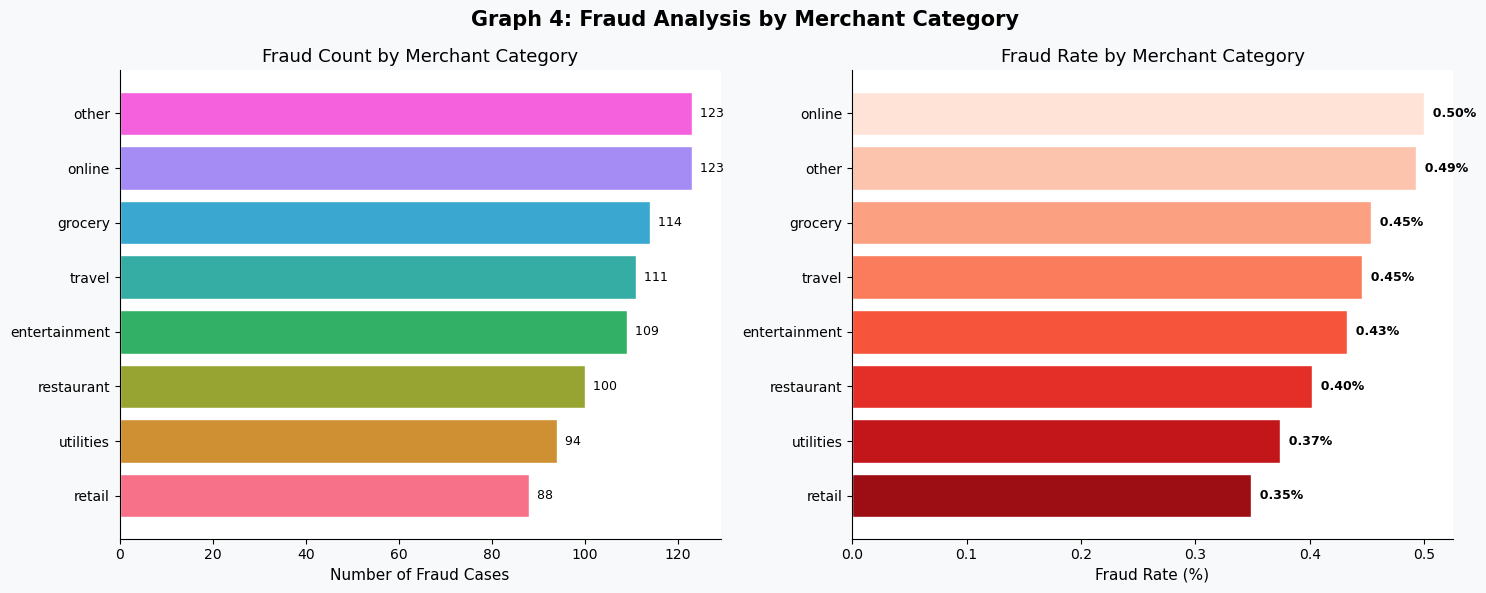

Graph 4 saved.


In [17]:
# ---------------------------------------------------------------
# GRAPH 4: Fraud by Merchant Category
# Which shopping category has the most fraud?
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Graph 4: Fraud Analysis by Merchant Category',
             fontsize=15, fontweight='bold')

merchant = df.groupby('merchant_category').agg(
    fraud_count=('is_fraud','sum'),
    total=('is_fraud','count')
).reset_index()
merchant['fraud_rate'] = merchant['fraud_count'] / merchant['total'] * 100
merchant = merchant.sort_values('fraud_count', ascending=True)

pal = sns.color_palette("husl", len(merchant))

# Left: Horizontal bar - fraud count
axes[0].barh(merchant['merchant_category'], merchant['fraud_count'],
             color=pal, edgecolor='white')
axes[0].set_xlabel('Number of Fraud Cases', fontsize=11)
axes[0].set_title('Fraud Count by Merchant Category', fontsize=13)
for i, (val, cat) in enumerate(zip(merchant['fraud_count'], merchant['merchant_category'])):
    axes[0].text(val, i, f'  {val:,}', va='center', fontsize=9)

# Right: Fraud rate bar chart
merchant_sorted = merchant.sort_values('fraud_rate', ascending=True)
axes[1].barh(merchant_sorted['merchant_category'], merchant_sorted['fraud_rate'],
             color=sns.color_palette("Reds_r", len(merchant)), edgecolor='white')
axes[1].set_xlabel('Fraud Rate (%)', fontsize=11)
axes[1].set_title('Fraud Rate by Merchant Category', fontsize=13)
for i, val in enumerate(merchant_sorted['fraud_rate']):
    axes[1].text(val, i, f'  {val:.2f}%', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('graph04_merchant_category.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 4 saved.")


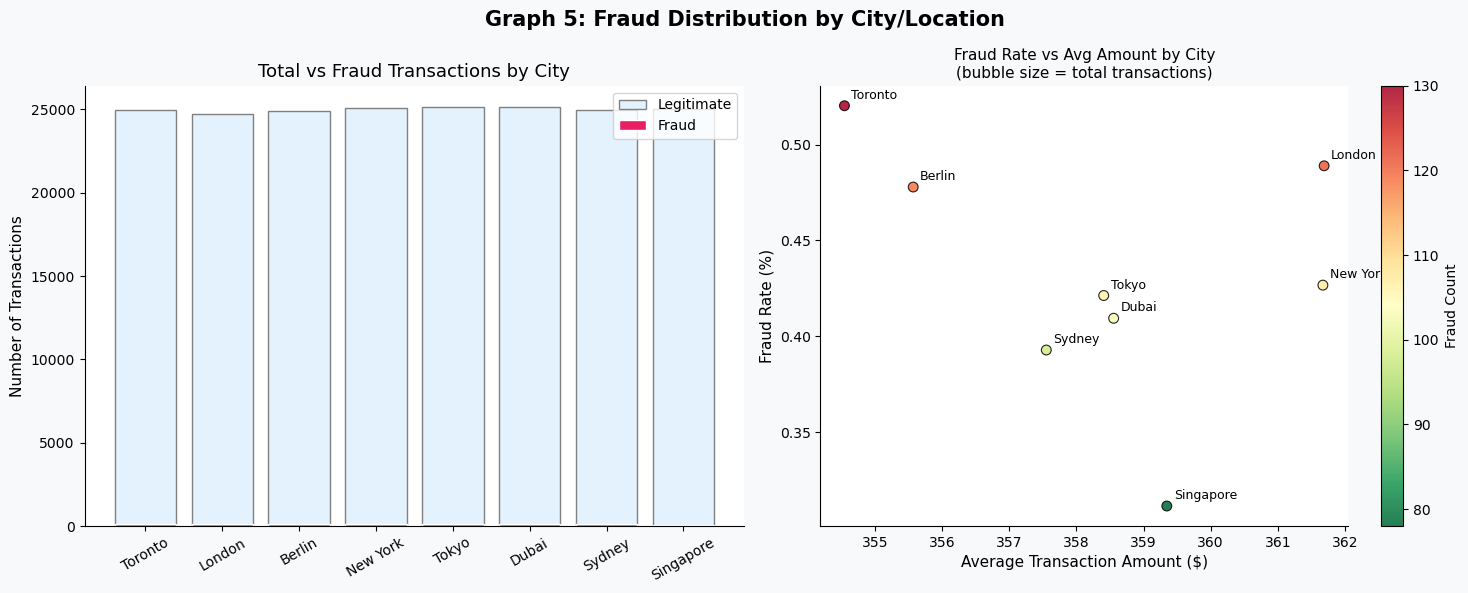

Graph 5 saved.


In [18]:
# ---------------------------------------------------------------
# GRAPH 5: Fraud by Location (City)
# Which cities have the most fraudulent transactions?
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Graph 5: Fraud Distribution by City/Location',
             fontsize=15, fontweight='bold')

location = df.groupby('location').agg(
    fraud=('is_fraud','sum'),
    total=('is_fraud','count'),
    avg_amount=('amount','mean')
).reset_index()
location['fraud_rate'] = location['fraud'] / location['total'] * 100
location = location.sort_values('fraud', ascending=False)

colors_loc = sns.color_palette("Set2", len(location))

# Left: Stacked bar - fraud vs total
axes[0].bar(location['location'], location['total'],
            color='#E3F2FD', label='Legitimate', edgecolor='grey')
axes[0].bar(location['location'], location['fraud'],
            color='#E91E63', label='Fraud', edgecolor='white')
axes[0].set_ylabel('Number of Transactions', fontsize=11)
axes[0].set_title('Total vs Fraud Transactions by City', fontsize=13)
axes[0].legend()
axes[0].tick_params(axis='x', rotation=30)

# Right: Bubble chart - fraud rate vs avg amount
scatter = axes[1].scatter(
    location['avg_amount'],
    location['fraud_rate'],
    s=location['total'] / 500,
    c=location['fraud'],
    cmap='RdYlGn_r',
    edgecolors='black',
    linewidth=0.8,
    alpha=0.85,
    zorder=3
)
for _, row in location.iterrows():
    axes[1].annotate(row['location'],
                     (row['avg_amount'], row['fraud_rate']),
                     textcoords='offset points', xytext=(5, 5),
                     fontsize=9)
plt.colorbar(scatter, ax=axes[1], label='Fraud Count')
axes[1].set_xlabel('Average Transaction Amount ($)', fontsize=11)
axes[1].set_ylabel('Fraud Rate (%)', fontsize=11)
axes[1].set_title('Fraud Rate vs Avg Amount by City\n(bubble size = total transactions)',
                  fontsize=11)

plt.tight_layout()
plt.savefig('graph05_location_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 5 saved.")


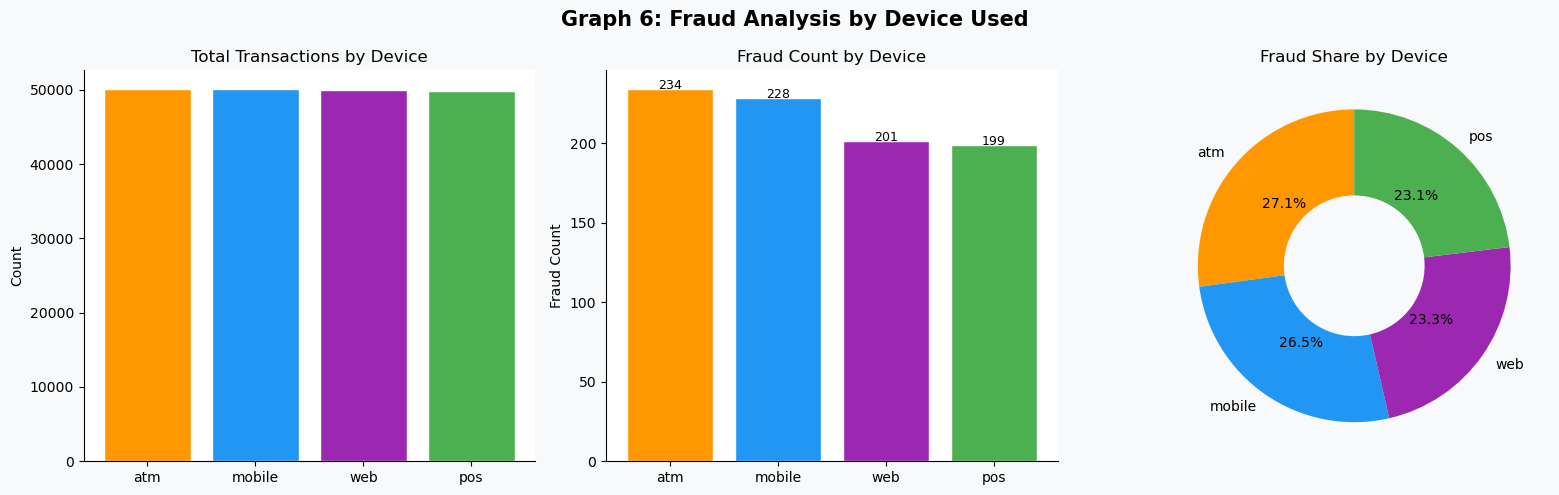

Graph 6 saved.


In [19]:
# ---------------------------------------------------------------
# GRAPH 6: Fraud by Device Type
# Mobile, ATM, POS (card machine), Web browser - which is riskiest?
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Graph 6: Fraud Analysis by Device Used',
             fontsize=15, fontweight='bold')

device = df.groupby('device_used').agg(
    fraud=('is_fraud','sum'),
    total=('is_fraud','count')
).reset_index()
device['fraud_rate'] = device['fraud'] / device['total'] * 100
device['legit'] = device['total'] - device['fraud']
device = device.sort_values('fraud', ascending=False)

device_colors = {'mobile':'#2196F3','atm':'#FF9800','pos':'#4CAF50','web':'#9C27B0'}
colors = [device_colors.get(d, '#607D8B') for d in device['device_used']]

# Left: Total count by device
axes[0].bar(device['device_used'], device['total'], color=colors, edgecolor='white')
axes[0].set_title('Total Transactions by Device', fontsize=12)
axes[0].set_ylabel('Count', fontsize=10)

# Centre: Fraud count by device
axes[1].bar(device['device_used'], device['fraud'], color=colors, edgecolor='white')
axes[1].set_title('Fraud Count by Device', fontsize=12)
axes[1].set_ylabel('Fraud Count', fontsize=10)
for i, val in enumerate(device['fraud']):
    axes[1].text(i, val, f'\n{val:,}', ha='center', fontsize=9)

# Right: Pie chart of fraud by device
axes[2].pie(device['fraud'], labels=device['device_used'], colors=colors,
            autopct='%1.1f%%', startangle=90,
            wedgeprops=dict(width=0.55))
axes[2].set_title('Fraud Share by Device', fontsize=12)

plt.tight_layout()
plt.savefig('graph06_device_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 6 saved.")


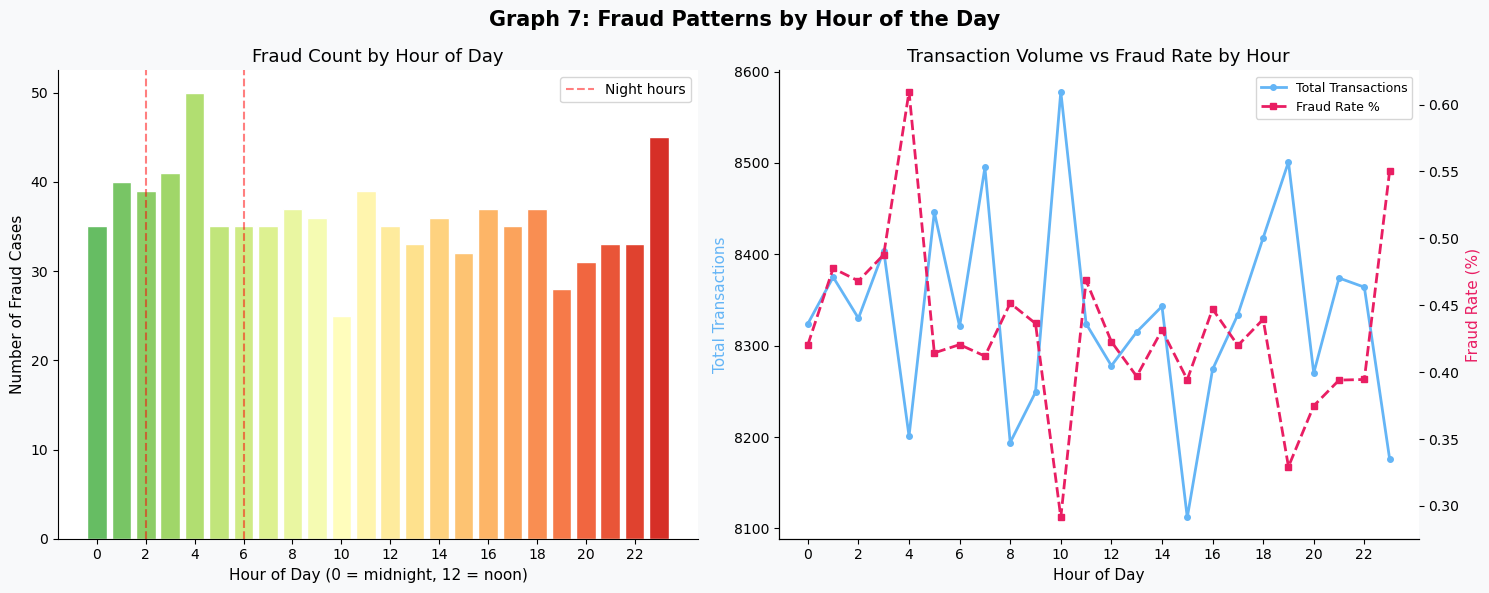

Graph 7 saved.


In [20]:
# ---------------------------------------------------------------
# GRAPH 7: Fraud by Hour of Day (Time Pattern Analysis)
# Finding the most dangerous hours for fraud
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Graph 7: Fraud Patterns by Hour of the Day',
             fontsize=15, fontweight='bold')

hourly = df.groupby('hour').agg(
    total=('is_fraud','count'),
    fraud=('is_fraud','sum')
).reset_index()
hourly['fraud_rate'] = hourly['fraud'] / hourly['total'] * 100

hours = hourly['hour']

# Left: Fraud count bar chart with hour-of-day colour gradient
bar_colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.9, 24))
axes[0].bar(hours, hourly['fraud'], color=bar_colors, edgecolor='white', width=0.8)
axes[0].set_xlabel('Hour of Day (0 = midnight, 12 = noon)', fontsize=11)
axes[0].set_ylabel('Number of Fraud Cases', fontsize=11)
axes[0].set_title('Fraud Count by Hour of Day', fontsize=13)
axes[0].set_xticks(range(0, 24, 2))
axes[0].axvline(x=2, color='red', linestyle='--', alpha=0.5, label='Night hours')
axes[0].axvline(x=6, color='red', linestyle='--', alpha=0.5)
axes[0].legend()

# Right: Dual axis - fraud count AND fraud rate
ax_twin = axes[1].twinx()
axes[1].plot(hours, hourly['total'], color='#64B5F6', linewidth=2,
             marker='o', markersize=4, label='Total Transactions')
axes[1].set_ylabel('Total Transactions', color='#64B5F6', fontsize=11)
ax_twin.plot(hours, hourly['fraud_rate'], color='#E91E63', linewidth=2,
             marker='s', markersize=4, linestyle='--', label='Fraud Rate %')
ax_twin.set_ylabel('Fraud Rate (%)', color='#E91E63', fontsize=11)
axes[1].set_xlabel('Hour of Day', fontsize=11)
axes[1].set_title('Transaction Volume vs Fraud Rate by Hour', fontsize=13)
axes[1].set_xticks(range(0, 24, 2))

# Combine legends
lines1, labels1 = axes[1].get_legend_handles_labels()
lines2, labels2 = ax_twin.get_legend_handles_labels()
axes[1].legend(lines1 + lines2, labels1 + labels2, fontsize=9)

plt.tight_layout()
plt.savefig('graph07_hour_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 7 saved.")


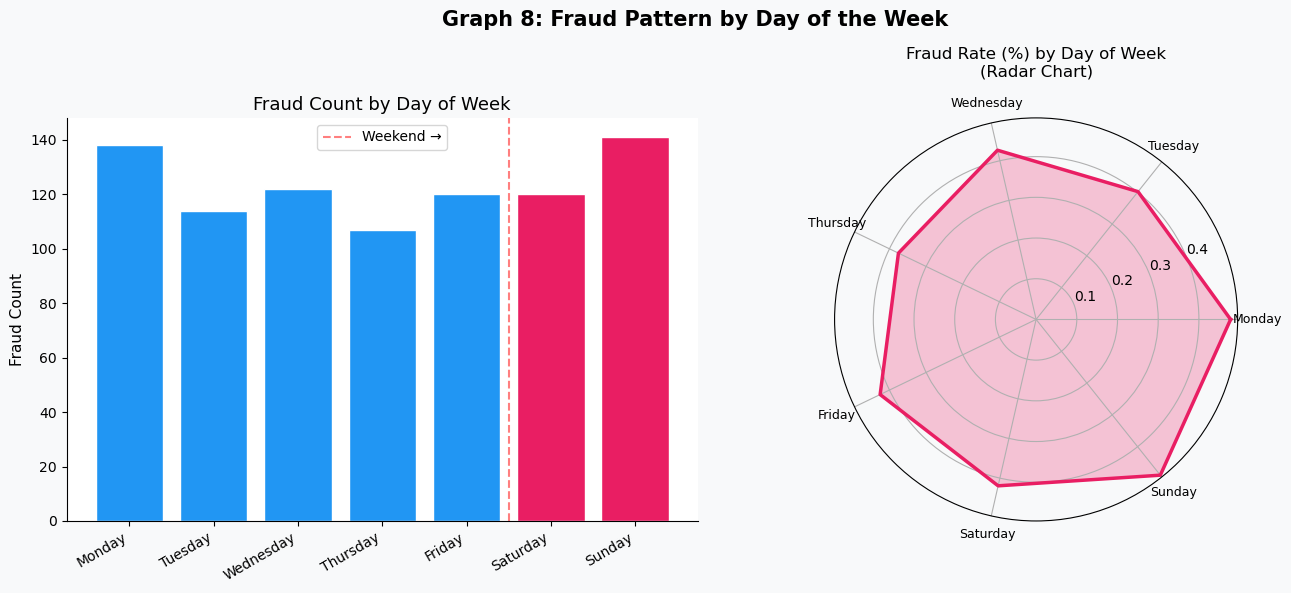

Graph 8 saved.


In [21]:
# ---------------------------------------------------------------
# GRAPH 8: Fraud by Day of the Week
# Are weekends more risky than weekdays?
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Graph 8: Fraud Pattern by Day of the Week',
             fontsize=15, fontweight='bold')

day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
daily = df.groupby('day_name').agg(
    total=('is_fraud','count'),
    fraud=('is_fraud','sum')
).reset_index()
daily['fraud_rate'] = daily['fraud'] / daily['total'] * 100
daily['day_name'] = pd.Categorical(daily['day_name'], categories=day_order, ordered=True)
daily = daily.sort_values('day_name')

day_colors = ['#2196F3','#2196F3','#2196F3','#2196F3','#2196F3','#E91E63','#E91E63']

# Left: Fraud count
axes[0].bar(daily['day_name'], daily['fraud'], color=day_colors, edgecolor='white')
axes[0].set_title('Fraud Count by Day of Week', fontsize=13)
axes[0].set_ylabel('Fraud Count', fontsize=11)
axes[0].set_xticklabels(day_order, rotation=30, ha='right')
axes[0].axvline(x=4.5, color='red', linestyle='--', alpha=0.5, label='Weekend →')
axes[0].legend()

# Right: Radar/polar chart of fraud rate
angles = np.linspace(0, 2*np.pi, 7, endpoint=False)
values = daily['fraud_rate'].values
values = np.concatenate([values, [values[0]]])
angles = np.concatenate([angles, [angles[0]]])

axes[1].remove()
ax_polar = fig.add_subplot(122, polar=True)
ax_polar.plot(angles, values, color='#E91E63', linewidth=2.5)
ax_polar.fill(angles, values, color='#E91E63', alpha=0.25)
ax_polar.set_xticks(angles[:-1])
ax_polar.set_xticklabels(day_order, fontsize=9)
ax_polar.set_title('Fraud Rate (%) by Day of Week\n(Radar Chart)', fontsize=12, pad=15)
ax_polar.set_facecolor('#f8f9fa')

plt.tight_layout()
plt.savefig('graph08_day_of_week.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 8 saved.")


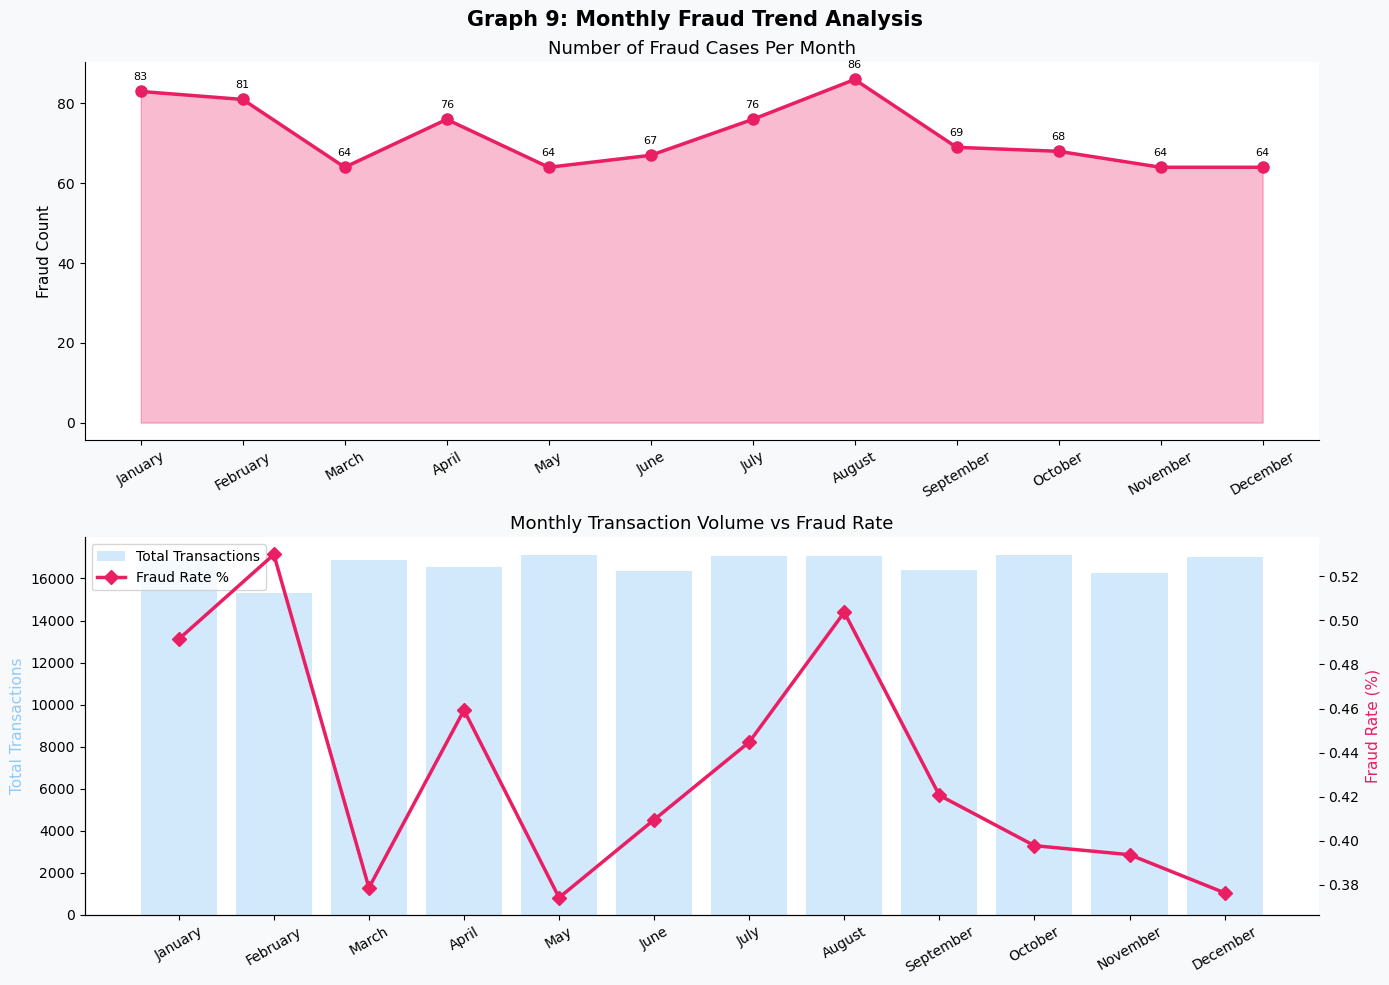

Graph 9 saved.


In [22]:
# ---------------------------------------------------------------
# GRAPH 9: Monthly Fraud Trend Over Time
# Shows how fraud numbers change month by month
# ---------------------------------------------------------------

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
fig.suptitle('Graph 9: Monthly Fraud Trend Analysis',
             fontsize=15, fontweight='bold')

monthly = df.groupby(['month', 'month_name']).agg(
    total=('is_fraud','count'),
    fraud=('is_fraud','sum'),
    fraud_amount=('amount', lambda x: x[df.loc[x.index,'is_fraud']==1].sum())
).reset_index()
monthly['fraud_rate'] = monthly['fraud'] / monthly['total'] * 100
monthly = monthly.sort_values('month')

months = range(len(monthly))

# Top: Line chart of fraud count per month
axes[0].fill_between(monthly['month_name'], monthly['fraud'], alpha=0.3, color='#E91E63')
axes[0].plot(monthly['month_name'], monthly['fraud'], color='#E91E63',
             linewidth=2.5, marker='o', markersize=8, zorder=5)
axes[0].set_title('Number of Fraud Cases Per Month', fontsize=13)
axes[0].set_ylabel('Fraud Count', fontsize=11)
axes[0].tick_params(axis='x', rotation=30)
for x, y in zip(monthly['month_name'], monthly['fraud']):
    axes[0].annotate(str(y), (x, y), textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=8)

# Bottom: Dual axis - fraud rate and total transactions
ax2 = axes[1].twinx()
axes[1].bar(monthly['month_name'], monthly['total'], alpha=0.4,
            color='#90CAF9', label='Total Transactions')
ax2.plot(monthly['month_name'], monthly['fraud_rate'],
         color='#E91E63', linewidth=2.5, marker='D',
         markersize=7, label='Fraud Rate %')
axes[1].set_ylabel('Total Transactions', fontsize=11, color='#90CAF9')
ax2.set_ylabel('Fraud Rate (%)', fontsize=11, color='#E91E63')
axes[1].set_title('Monthly Transaction Volume vs Fraud Rate', fontsize=13)
axes[1].tick_params(axis='x', rotation=30)
lines1, lab1 = axes[1].get_legend_handles_labels()
lines2, lab2 = ax2.get_legend_handles_labels()
axes[1].legend(lines1+lines2, lab1+lab2, loc='upper left')

plt.tight_layout()
plt.savefig('graph09_monthly_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 9 saved.")


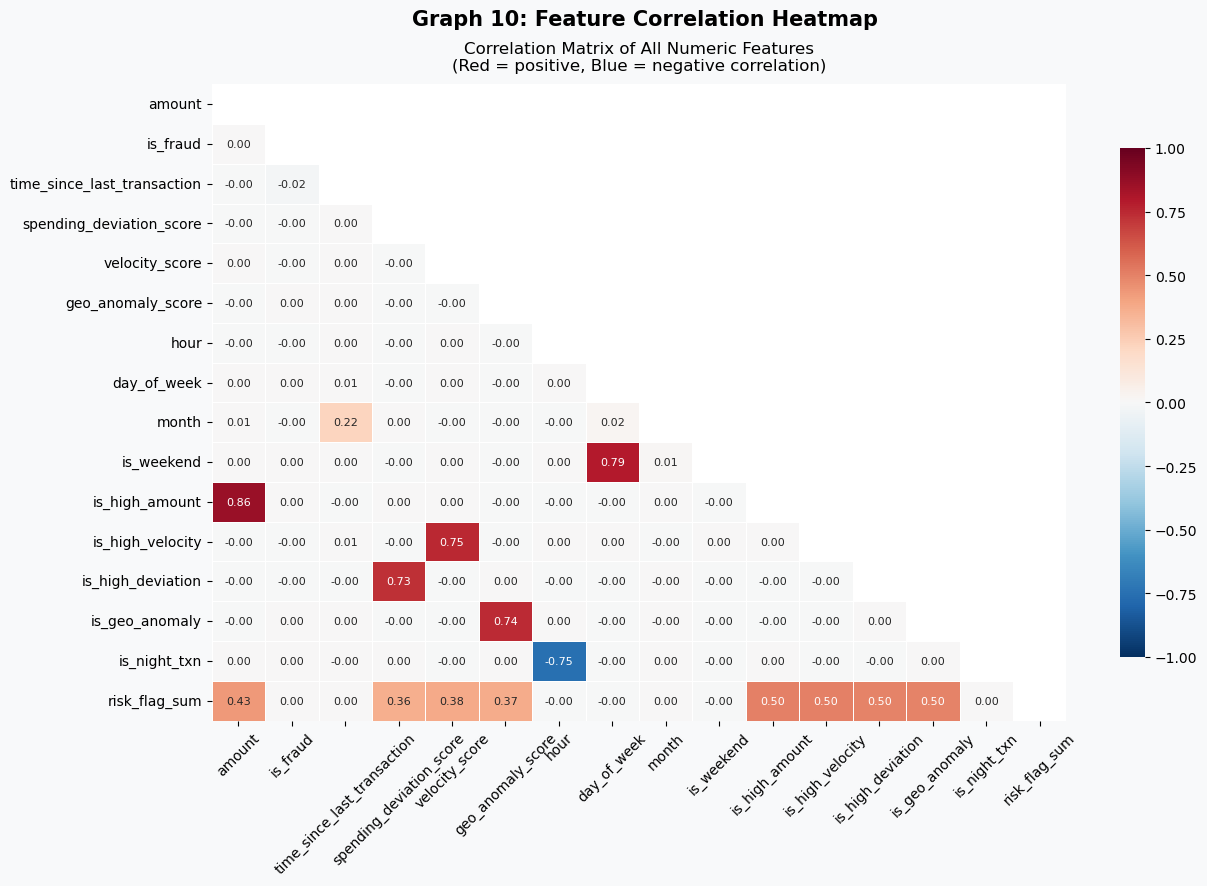

Graph 10 saved.


In [23]:
# ---------------------------------------------------------------
# GRAPH 10: Correlation Heatmap
# Shows which features are related to each other and to fraud
# Higher correlation with is_fraud = more useful for prediction
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 9))
fig.suptitle('Graph 10: Feature Correlation Heatmap',
             fontsize=15, fontweight='bold')

# Select only numeric columns for correlation
numeric_cols = ['amount', 'is_fraud', 'time_since_last_transaction',
                'spending_deviation_score', 'velocity_score', 'geo_anomaly_score',
                'hour', 'day_of_week', 'month', 'is_weekend',
                'is_high_amount', 'is_high_velocity', 'is_high_deviation',
                'is_geo_anomaly', 'is_night_txn', 'risk_flag_sum']

corr_matrix = df[numeric_cols].corr().round(3)

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # Hide upper triangle

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    ax=ax,
    annot_kws={'size': 8},
    cbar_kws={'shrink': 0.8}
)
ax.set_title('Correlation Matrix of All Numeric Features\n(Red = positive, Blue = negative correlation)',
             fontsize=12, pad=10)
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('graph10_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 10 saved.")


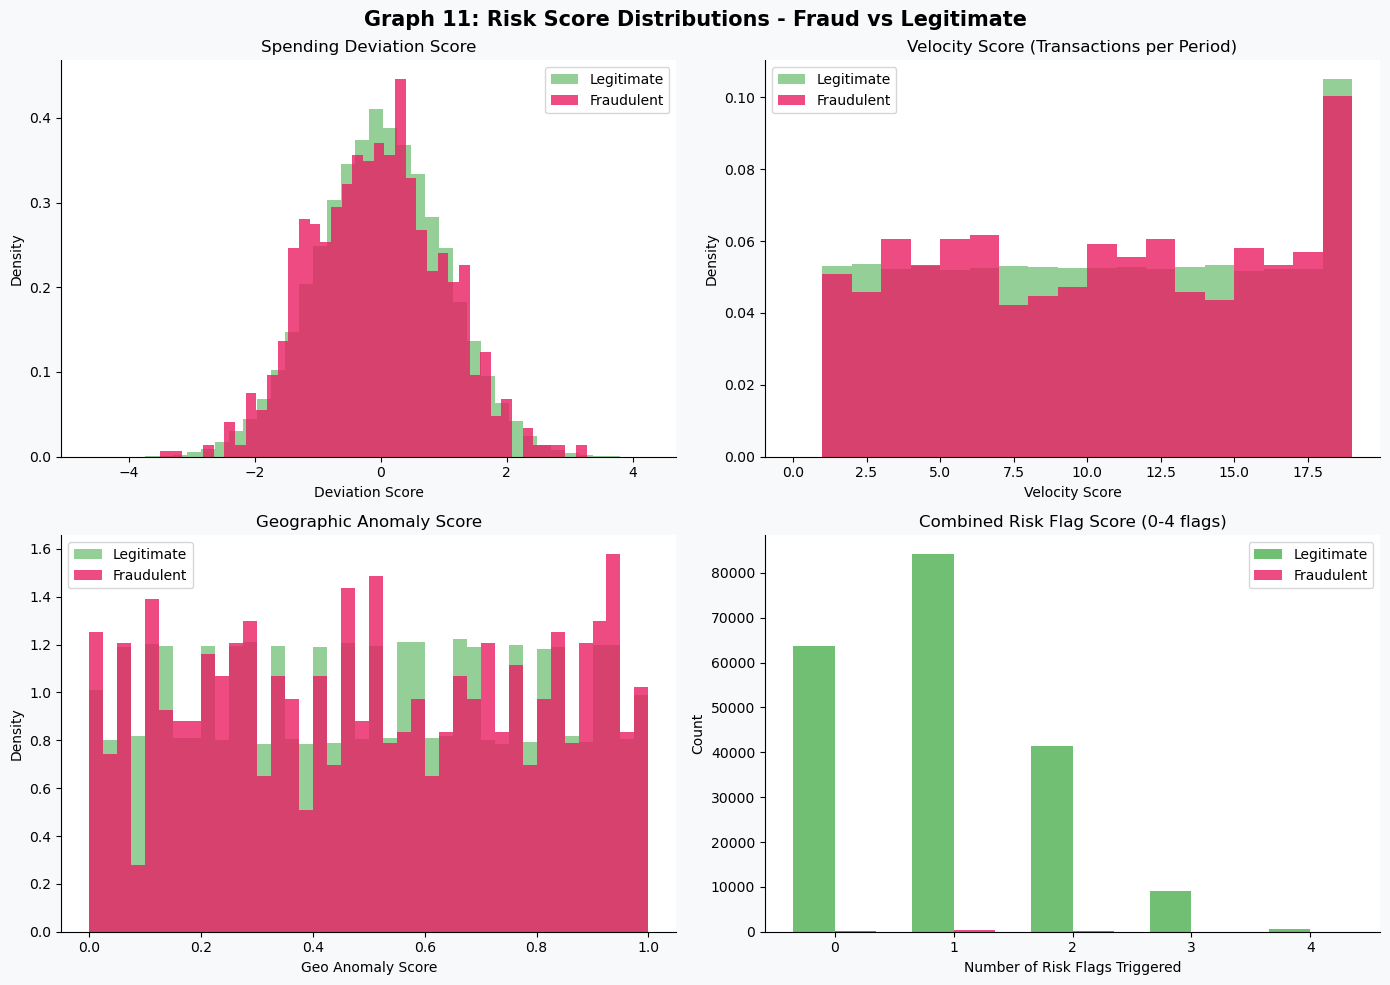

Graph 11 saved.


In [24]:
# ---------------------------------------------------------------
# GRAPH 11: Risk Score Analysis (Spending Deviation & Velocity)
# Shows how the risk scores differ between fraud and legitimate
# ---------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Graph 11: Risk Score Distributions - Fraud vs Legitimate',
             fontsize=15, fontweight='bold')

fraud_df = df[df['is_fraud']==1]
legit_df = df[df['is_fraud']==0]

# Plot 1: Spending deviation distribution
axes[0,0].hist(legit_df['spending_deviation_score'], bins=40, alpha=0.6,
               color='#4CAF50', label='Legitimate', density=True)
axes[0,0].hist(fraud_df['spending_deviation_score'], bins=40, alpha=0.8,
               color='#E91E63', label='Fraudulent', density=True)
axes[0,0].set_title('Spending Deviation Score', fontsize=12)
axes[0,0].set_xlabel('Deviation Score', fontsize=10)
axes[0,0].set_ylabel('Density', fontsize=10)
axes[0,0].legend()

# Plot 2: Velocity score distribution
axes[0,1].hist(legit_df['velocity_score'], bins=range(0,20), alpha=0.6,
               color='#4CAF50', label='Legitimate', density=True)
axes[0,1].hist(fraud_df['velocity_score'], bins=range(0,20), alpha=0.8,
               color='#E91E63', label='Fraudulent', density=True)
axes[0,1].set_title('Velocity Score (Transactions per Period)', fontsize=12)
axes[0,1].set_xlabel('Velocity Score', fontsize=10)
axes[0,1].set_ylabel('Density', fontsize=10)
axes[0,1].legend()

# Plot 3: Geo anomaly distribution
axes[1,0].hist(legit_df['geo_anomaly_score'], bins=40, alpha=0.6,
               color='#4CAF50', label='Legitimate', density=True)
axes[1,0].hist(fraud_df['geo_anomaly_score'], bins=40, alpha=0.8,
               color='#E91E63', label='Fraudulent', density=True)
axes[1,0].set_title('Geographic Anomaly Score', fontsize=12)
axes[1,0].set_xlabel('Geo Anomaly Score', fontsize=10)
axes[1,0].set_ylabel('Density', fontsize=10)
axes[1,0].legend()

# Plot 4: Risk flag sum comparison
risk_fraud = fraud_df['risk_flag_sum'].value_counts().sort_index()
risk_legit = legit_df['risk_flag_sum'].value_counts().sort_index()
x = np.arange(5)
width = 0.35
axes[1,1].bar(x - width/2, [risk_legit.get(i,0) for i in range(5)],
              width, color='#4CAF50', label='Legitimate', alpha=0.8)
axes[1,1].bar(x + width/2, [risk_fraud.get(i,0) for i in range(5)],
              width, color='#E91E63', label='Fraudulent', alpha=0.8)
axes[1,1].set_title('Combined Risk Flag Score (0-4 flags)', fontsize=12)
axes[1,1].set_xlabel('Number of Risk Flags Triggered', fontsize=10)
axes[1,1].set_ylabel('Count', fontsize=10)
axes[1,1].set_xticks(x)
axes[1,1].legend()

plt.tight_layout()
plt.savefig('graph11_risk_scores.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 11 saved.")


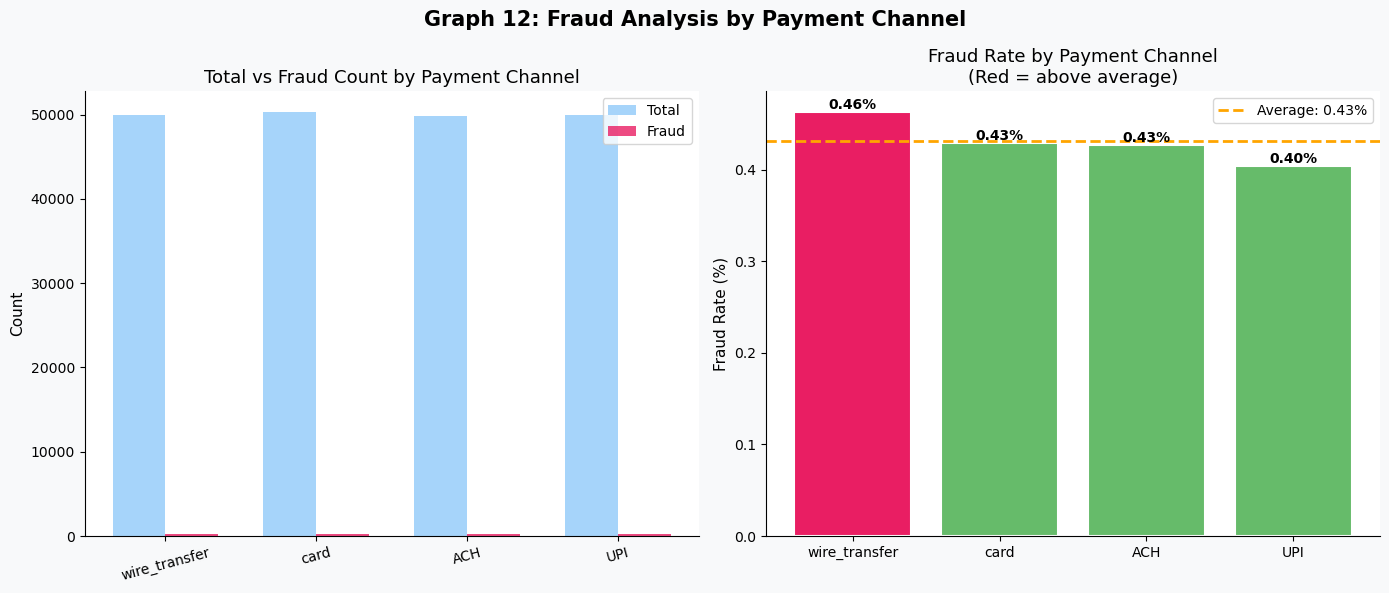

Graph 12 saved.


In [25]:
# ---------------------------------------------------------------
# GRAPH 12: Fraud by Payment Channel
# Card, ACH, Wire Transfer, UPI - which channel has most fraud?
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Graph 12: Fraud Analysis by Payment Channel',
             fontsize=15, fontweight='bold')

channel = df.groupby('payment_channel').agg(
    total=('is_fraud','count'),
    fraud=('is_fraud','sum'),
    total_amount=('amount','sum'),
    fraud_amount=('amount', lambda x: x[df.loc[x.index,'is_fraud']==1].sum())
).reset_index()
channel['fraud_rate'] = channel['fraud'] / channel['total'] * 100
channel = channel.sort_values('fraud_rate', ascending=False)

channel_colors = sns.color_palette("Set1", len(channel))

# Left: grouped bar chart (fraud count and total)
x = np.arange(len(channel))
width = 0.35
axes[0].bar(x - width/2, channel['total'], width, color='#90CAF9',
            label='Total', alpha=0.8)
axes[0].bar(x + width/2, channel['fraud'], width, color='#E91E63',
            label='Fraud', alpha=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(channel['payment_channel'], rotation=15)
axes[0].set_title('Total vs Fraud Count by Payment Channel', fontsize=13)
axes[0].set_ylabel('Count', fontsize=11)
axes[0].legend()

# Right: Fraud rate with colour coding
bar_colors_ch = ['#E91E63' if r > channel['fraud_rate'].mean() else '#66BB6A'
                 for r in channel['fraud_rate']]
bars = axes[1].bar(channel['payment_channel'], channel['fraud_rate'],
                   color=bar_colors_ch, edgecolor='white', linewidth=1.5)
axes[1].axhline(y=channel['fraud_rate'].mean(), color='orange', linestyle='--',
                linewidth=2, label=f"Average: {channel['fraud_rate'].mean():.2f}%")
axes[1].set_title('Fraud Rate by Payment Channel\n(Red = above average)', fontsize=13)
axes[1].set_ylabel('Fraud Rate (%)', fontsize=11)
axes[1].legend()
for bar, val in zip(bars, channel['fraud_rate']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f'{val:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('graph12_payment_channel.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 12 saved.")


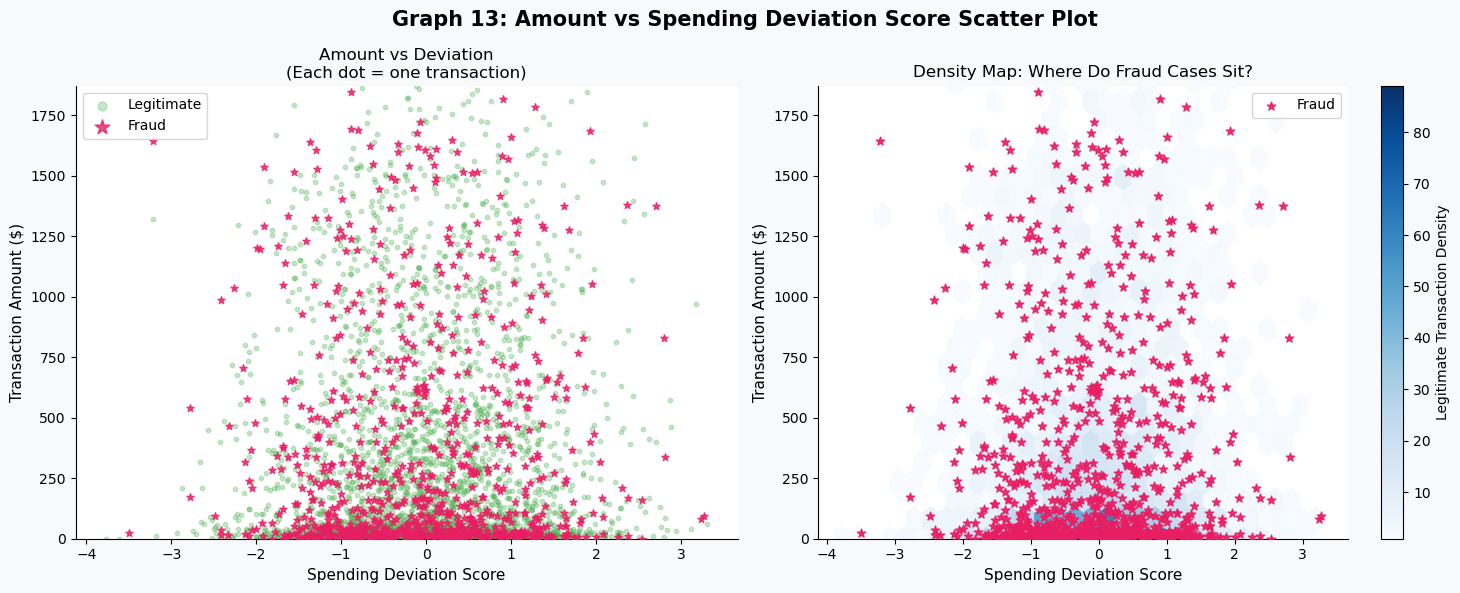

Graph 13 saved.


In [26]:
# ---------------------------------------------------------------
# GRAPH 13: Scatter Plot - Amount vs Deviation Score
# Shows the relationship between transaction amount and spending deviation
# Helps visualise how fraud cases cluster differently from normal cases
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Graph 13: Amount vs Spending Deviation Score Scatter Plot',
             fontsize=15, fontweight='bold')

# Sample to speed up scatter plotting (too many points otherwise)
sample_legit = df[df['is_fraud']==0].sample(3000, random_state=42)
sample_fraud  = df[df['is_fraud']==1]

# Left: Simple scatter
axes[0].scatter(sample_legit['spending_deviation_score'], sample_legit['amount'],
                alpha=0.3, color='#4CAF50', s=10, label='Legitimate')
axes[0].scatter(sample_fraud['spending_deviation_score'], sample_fraud['amount'],
                alpha=0.8, color='#E91E63', s=30, label='Fraud', marker='*', zorder=5)
axes[0].set_xlabel('Spending Deviation Score', fontsize=11)
axes[0].set_ylabel('Transaction Amount ($)', fontsize=11)
axes[0].set_title('Amount vs Deviation\n(Each dot = one transaction)', fontsize=12)
axes[0].set_ylim(0, df['amount'].quantile(0.99))
axes[0].legend(markerscale=2)

# Right: Hexbin density plot for legitimate only (shows where they cluster)
hb = axes[1].hexbin(sample_legit['spending_deviation_score'],
                    sample_legit['amount'],
                    gridsize=30, cmap='Blues', mincnt=1)
axes[1].scatter(sample_fraud['spending_deviation_score'], sample_fraud['amount'],
                alpha=0.9, color='#E91E63', s=40, label='Fraud', zorder=5, marker='*')
plt.colorbar(hb, ax=axes[1], label='Legitimate Transaction Density')
axes[1].set_xlabel('Spending Deviation Score', fontsize=11)
axes[1].set_ylabel('Transaction Amount ($)', fontsize=11)
axes[1].set_title('Density Map: Where Do Fraud Cases Sit?', fontsize=12)
axes[1].set_ylim(0, df['amount'].quantile(0.99))
axes[1].legend()

plt.tight_layout()
plt.savefig('graph13_scatter_deviation.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 13 saved.")


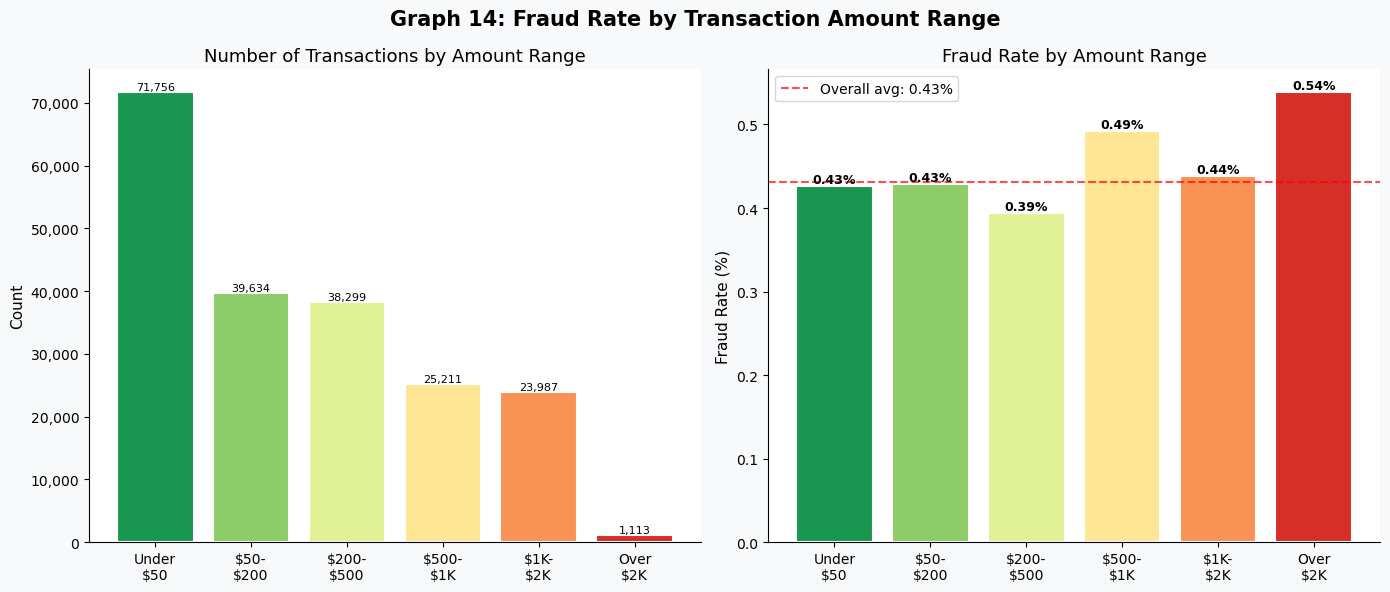

Graph 14 saved.


In [27]:
# ---------------------------------------------------------------
# GRAPH 14: Transaction Amount Bucket Analysis
# Grouping transactions by amount range and checking fraud rate per group
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Graph 14: Fraud Rate by Transaction Amount Range',
             fontsize=15, fontweight='bold')

# Create amount buckets
bins   = [0, 50, 200, 500, 1000, 2000, np.inf]
labels = ['Under\n$50', '$50-\n$200', '$200-\n$500',
          '$500-\n$1K', '$1K-\n$2K', 'Over\n$2K']
df['amount_bucket'] = pd.cut(df['amount'], bins=bins, labels=labels)

bucket_stats = df.groupby('amount_bucket', observed=True).agg(
    total=('is_fraud','count'),
    fraud=('is_fraud','sum')
).reset_index()
bucket_stats['fraud_rate'] = bucket_stats['fraud'] / bucket_stats['total'] * 100

gradient_colors = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(bucket_stats)))

# Left: Transaction count per bucket
bars = axes[0].bar(bucket_stats['amount_bucket'], bucket_stats['total'],
                   color=gradient_colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('Number of Transactions by Amount Range', fontsize=13)
axes[0].set_ylabel('Count', fontsize=11)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'))
for bar, val in zip(bars, bucket_stats['total']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f'{val:,}', ha='center', va='bottom', fontsize=8)

# Right: Fraud rate per bucket
bars2 = axes[1].bar(bucket_stats['amount_bucket'], bucket_stats['fraud_rate'],
                    color=gradient_colors, edgecolor='white', linewidth=1.5)
axes[1].set_title('Fraud Rate by Amount Range', fontsize=13)
axes[1].set_ylabel('Fraud Rate (%)', fontsize=11)
axes[1].axhline(y=df['is_fraud'].mean()*100, color='red', linestyle='--',
                alpha=0.7, label=f"Overall avg: {df['is_fraud'].mean()*100:.2f}%")
axes[1].legend()
for bar, val in zip(bars2, bucket_stats['fraud_rate']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f'{val:.2f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('graph14_amount_buckets.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 14 saved.")


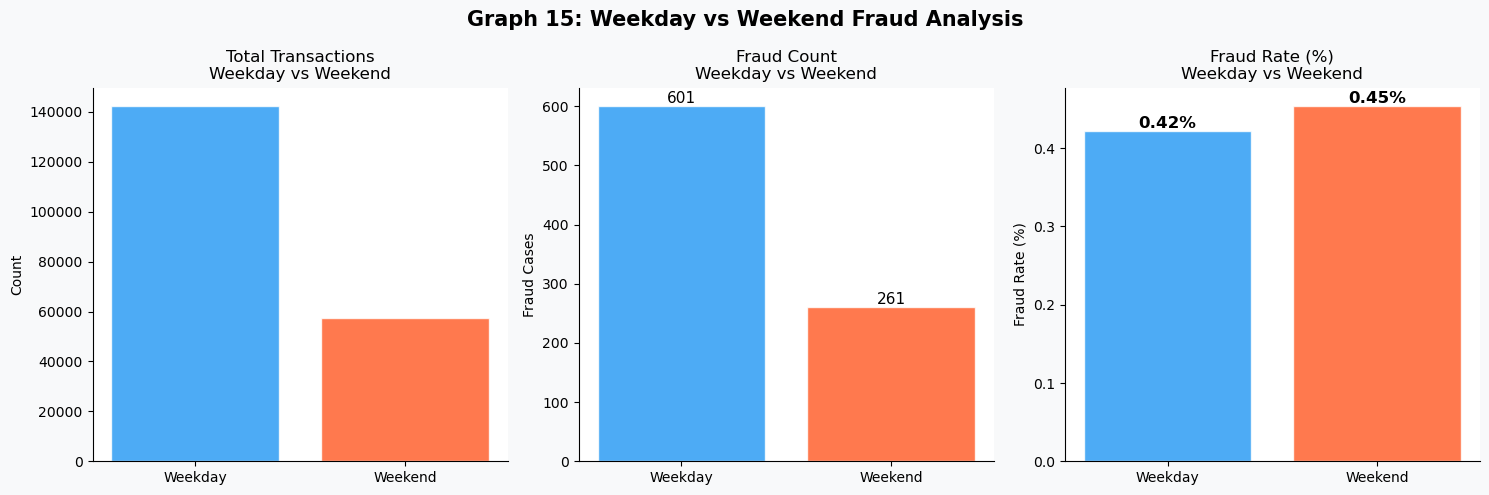

Graph 15 saved.


In [28]:
# ---------------------------------------------------------------
# GRAPH 15: Weekday vs Weekend Fraud Comparison
# Do fraudsters prefer weekends when bank monitoring may be lower?
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Graph 15: Weekday vs Weekend Fraud Analysis',
             fontsize=15, fontweight='bold')

weekend_stats = df.groupby('is_weekend').agg(
    total=('is_fraud','count'),
    fraud=('is_fraud','sum'),
    avg_amount=('amount','mean')
).reset_index()
weekend_stats['fraud_rate'] = weekend_stats['fraud'] / weekend_stats['total'] * 100
weekend_stats['label'] = weekend_stats['is_weekend'].map({0:'Weekday', 1:'Weekend'})

wk_colors = ['#2196F3', '#FF5722']

# Left: Count comparison
for i, (label, row) in enumerate(zip(['Weekday','Weekend'], weekend_stats.itertuples())):
    axes[0].bar(label, row.total, color=wk_colors[i], alpha=0.8, edgecolor='white')
axes[0].set_title('Total Transactions\nWeekday vs Weekend', fontsize=12)
axes[0].set_ylabel('Count', fontsize=10)

# Middle: Fraud count comparison
for i, (label, row) in enumerate(zip(['Weekday','Weekend'], weekend_stats.itertuples())):
    axes[1].bar(label, row.fraud, color=wk_colors[i], alpha=0.8, edgecolor='white')
    axes[1].text(i, row.fraud, f'{row.fraud:,}', ha='center', va='bottom', fontsize=11)
axes[1].set_title('Fraud Count\nWeekday vs Weekend', fontsize=12)
axes[1].set_ylabel('Fraud Cases', fontsize=10)

# Right: Fraud rate
for i, (label, row) in enumerate(zip(['Weekday','Weekend'], weekend_stats.itertuples())):
    axes[2].bar(label, row.fraud_rate, color=wk_colors[i], alpha=0.8, edgecolor='white')
    axes[2].text(i, row.fraud_rate, f'{row.fraud_rate:.2f}%',
                 ha='center', va='bottom', fontsize=12, fontweight='bold')
axes[2].set_title('Fraud Rate (%)\nWeekday vs Weekend', fontsize=12)
axes[2].set_ylabel('Fraud Rate (%)', fontsize=10)

plt.tight_layout()
plt.savefig('graph15_weekend_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 15 saved.")


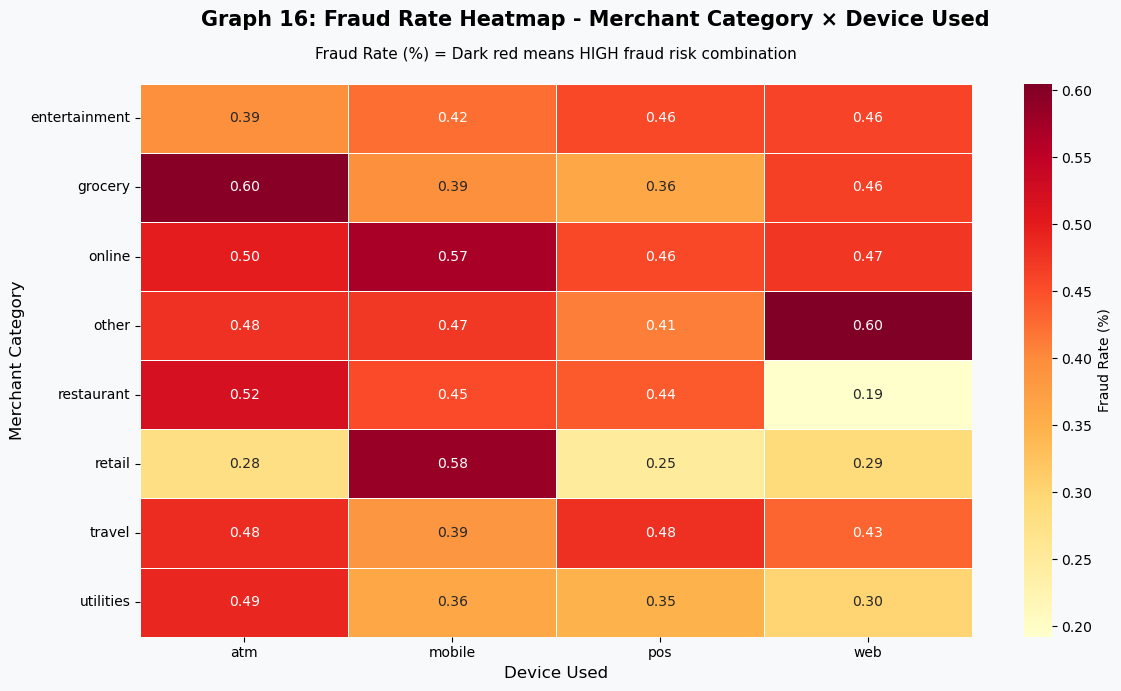

Graph 16 saved.


In [29]:
# ---------------------------------------------------------------
# GRAPH 16 : Merchant Category × Device Used Heatmap
# Which combination of merchant and device has the highest fraud rate?
# This is a matrix/pivot heatmap - great for finding fraud hotspots
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))
fig.suptitle('Graph 16: Fraud Rate Heatmap - Merchant Category × Device Used',
             fontsize=15, fontweight='bold')

# Build pivot table: rows=merchant, columns=device, values=fraud rate
pivot = df.groupby(['merchant_category','device_used'])['is_fraud'].mean() * 100
pivot = pivot.unstack(fill_value=0).round(3)

sns.heatmap(
    pivot,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Fraud Rate (%)'},
    ax=ax,
    annot_kws={'size': 10}
)
ax.set_title('Fraud Rate (%) = Dark red means HIGH fraud risk combination\n',
             fontsize=11)
ax.set_xlabel('Device Used', fontsize=12)
ax.set_ylabel('Merchant Category', fontsize=12)
ax.tick_params(axis='x', rotation=0)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('graph16_merchant_device_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 16 saved.")


## Section 6: Machine Learning Models

In [30]:
# ---------------------------------------------------------------
# Step 6.1: Prepare features and target variable
# I need to convert all text (categorical) columns to numbers
# because ML models only understand numbers
# ---------------------------------------------------------------

print("Preparing dataset for machine learning...")

# These are the columns I will use to predict fraud (features)
feature_cols = [
    'amount',
    'time_since_last_transaction',
    'spending_deviation_score',
    'velocity_score',
    'geo_anomaly_score',
    'hour',
    'day_of_week',
    'month',
    'is_weekend',
    'is_high_amount',
    'is_high_velocity',
    'is_high_deviation',
    'is_geo_anomaly',
    'is_night_txn',
    'is_quick_followup',
    'risk_flag_sum',
    # Categorical columns - will be label encoded below
    'transaction_type',
    'merchant_category',
    'location',
    'device_used',
    'payment_channel',
]

# Copy the dataframe for ML 
df_ml = df[feature_cols + ['is_fraud']].copy()

# Label Encode categorical columns
# This converts text like 'mobile' → 1, 'atm' → 2 etc.
le = LabelEncoder()
categorical_cols = ['transaction_type', 'merchant_category',
                    'location', 'device_used', 'payment_channel']

for col in categorical_cols:
    df_ml[col] = le.fit_transform(df_ml[col].astype(str))
    print(f"Encoded '{col}': {df[col].unique()}")

# Separate features (X) and target (y)
X = df_ml[feature_cols]
y = df_ml['is_fraud']

print(f"\nFeature matrix shape: {X.shape}")
print(f"Target variable shape: {y.shape}")
print(f"Fraud cases in data: {y.sum()} ({y.mean()*100:.2f}%)")


Preparing dataset for machine learning...
Encoded 'transaction_type': ['withdrawal' 'deposit' 'transfer' 'payment']
Encoded 'merchant_category': ['utilities' 'online' 'other' 'entertainment' 'travel' 'grocery' 'retail'
 'restaurant']
Encoded 'location': ['Tokyo' 'Toronto' 'London' 'Sydney' 'Berlin' 'Dubai' 'New York'
 'Singapore']
Encoded 'device_used': ['mobile' 'atm' 'pos' 'web']
Encoded 'payment_channel': ['card' 'ACH' 'wire_transfer' 'UPI']

Feature matrix shape: (200000, 21)
Target variable shape: (200000,)
Fraud cases in data: 862 (0.43%)


In [31]:
# ---------------------------------------------------------------
# Step 6.2: Split data into training and testing sets
# 80% of data used to train models
# 20% of data held back to test how well models work
# stratify=y ensures both sets have the same fraud ratio
# ---------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train/Test Split:")
print(f"  Training set  : {X_train.shape[0]:,} rows ({X_train.shape[0]/len(X)*100:.0f}%)")
print(f"  Testing set   : {X_test.shape[0]:,} rows ({X_test.shape[0]/len(X)*100:.0f}%)")
print(f"  Fraud in train: {y_train.sum()} ({y_train.mean()*100:.2f}%)")
print(f"  Fraud in test : {y_test.sum()} ({y_test.mean()*100:.2f}%)")


Train/Test Split:
  Training set  : 160,000 rows (80%)
  Testing set   : 40,000 rows (20%)
  Fraud in train: 690 (0.43%)
  Fraud in test : 172 (0.43%)


In [32]:
# ---------------------------------------------------------------
# Step 6.3: Apply SMOTE to fix class imbalance
# SMOTE = Synthetic Minority Oversampling Technique
# It creates fake (synthetic) fraud examples to balance the dataset
# This is important because only ~1% are fraud - models would just predict 0 always!
# ---------------------------------------------------------------

print("Before SMOTE:")
print(f"  Legitimate: {(y_train==0).sum():,}")
print(f"  Fraud     : {(y_train==1).sum():,}")

# Apply SMOTE only on the training set (NOT on test set - that would be cheating!)
smote = SMOTE(random_state=42, sampling_strategy=0.5)  # 50% fraud in training
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("\nAfter SMOTE:")
print(f"  Legitimate: {(y_train_sm==0).sum():,}")
print(f"  Fraud     : {(y_train_sm==1).sum():,}")
print(f"  New training size: {len(X_train_sm):,}")


Before SMOTE:
  Legitimate: 159,310
  Fraud     : 690

After SMOTE:
  Legitimate: 159,310
  Fraud     : 79,655
  New training size: 238,965


In [33]:
# ---------------------------------------------------------------
# Step 6.4: Scale the feature values
# StandardScaler makes all features have mean=0 and std=1
# This is needed for Logistic Regression, KNN, and SVM
# Tree-based models (Decision Tree, Random Forest) don't need scaling
# ---------------------------------------------------------------

scaler = StandardScaler()

# Fit the scaler on training data only (then transform both sets)
X_train_scaled = scaler.fit_transform(X_train_sm)
X_test_scaled  = scaler.transform(X_test)

print("Feature scaling complete!")
print(f"Mean of amount column after scaling: {X_train_scaled[:, 0].mean():.4f}")
print(f"Std  of amount column after scaling: {X_train_scaled[:, 0].std():.4f}")
print("(Both should be close to 0.0 and 1.0 respectively)")


Feature scaling complete!
Mean of amount column after scaling: -0.0000
Std  of amount column after scaling: 1.0000
(Both should be close to 0.0 and 1.0 respectively)


In [34]:
# ---------------------------------------------------------------
# Step 6.5: Define a helper function to evaluate any model
# This function trains the model, predicts on test data,
# and returns all the performance metrics I care about
# ---------------------------------------------------------------

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, use_scaled=False):
    '''
    Train and evaluate a machine learning model.

    name       : Model display name (string)
    model      : Sklearn model object
    X_tr/y_tr  : Training features and labels
    X_te/y_te  : Testing features and labels
    use_scaled : True = use scaled data (for Logistic Regression, KNN, SVM)
    '''
    # Use scaled data for models that need it
    if use_scaled:
        X_tr_use = scaler.fit_transform(X_tr)
        X_te_use = X_test_scaled
    else:
        X_tr_use = X_tr
        X_te_use = X_te

    # Train the model
    print(f"Training {name}...")
    model.fit(X_tr_use, y_tr)

    # Predict on test data
    y_pred      = model.predict(X_te_use)
    y_pred_prob = model.predict_proba(X_te_use)[:, 1] if hasattr(model, 'predict_proba') else None

    # Calculate all metrics
    acc  = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, zero_division=0)
    rec  = recall_score(y_te, y_pred, zero_division=0)
    f1   = f1_score(y_te, y_pred, zero_division=0)
    auc  = roc_auc_score(y_te, y_pred_prob) if y_pred_prob is not None else 0.0
    cm   = confusion_matrix(y_te, y_pred)

    print(f"  Accuracy : {acc:.4f}  ({acc*100:.2f}%)")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}  ← Most important for fraud detection!")
    print(f"  F1-Score : {f1:.4f}")
    print(f"  ROC-AUC  : {auc:.4f}")
    print()

    return {
        'name'     : name,
        'model'    : model,
        'y_pred'   : y_pred,
        'y_prob'   : y_pred_prob,
        'accuracy' : round(acc, 4),
        'precision': round(prec, 4),
        'recall'   : round(rec, 4),
        'f1'       : round(f1, 4),
        'auc'      : round(auc, 4),
        'cm'       : cm,
    }

print("Evaluation function defined successfully!")


Evaluation function defined successfully!


In [35]:
# ---------------------------------------------------------------
# Step 6.6: Train Model 1 - Logistic Regression
# Simple but fast linear model - good baseline
# Uses log-odds to separate fraud from legitimate
# ---------------------------------------------------------------

lr_result = evaluate_model(
    name        = "Logistic Regression",
    model       = LogisticRegression(max_iter=500, C=1.0, random_state=42),
    X_tr        = X_train_sm,
    y_tr        = y_train_sm,
    X_te        = X_test,
    y_te        = y_test,
    use_scaled  = True
)


Training Logistic Regression...
  Accuracy : 0.9484  (94.84%)
  Precision: 0.0403
  Recall   : 0.4826  ← Most important for fraud detection!
  F1-Score : 0.0744
  ROC-AUC  : 0.8414



In [36]:
# ---------------------------------------------------------------
# Step 6.7: Train Model 2 - Decision Tree
# Creates a tree of yes/no questions to classify transactions
# Easy to understand and visualise
# ---------------------------------------------------------------

dt_result = evaluate_model(
    name   = "Decision Tree",
    model  = DecisionTreeClassifier(max_depth=10, min_samples_leaf=10, random_state=42),
    X_tr   = X_train_sm,
    y_tr   = y_train_sm,
    X_te   = X_test,
    y_te   = y_test,
    use_scaled = False
)


Training Decision Tree...
  Accuracy : 0.9496  (94.96%)
  Precision: 0.0458
  Recall   : 0.5407  ← Most important for fraud detection!
  F1-Score : 0.0845
  ROC-AUC  : 0.8336



In [37]:
# ---------------------------------------------------------------
# Step 6.8: Train Model 3 - Random Forest
# Builds many decision trees and combines their results
# Usually more accurate than a single decision tree
# ---------------------------------------------------------------

rf_result = evaluate_model(
    name   = "Random Forest",
    model  = RandomForestClassifier(n_estimators=100, max_depth=12,
                                    min_samples_leaf=5, random_state=42, n_jobs=-1),
    X_tr   = X_train_sm,
    y_tr   = y_train_sm,
    X_te   = X_test,
    y_te   = y_test,
    use_scaled = False
)


Training Random Forest...
  Accuracy : 0.9639  (96.39%)
  Precision: 0.0509
  Recall   : 0.4186  ← Most important for fraud detection!
  F1-Score : 0.0908
  ROC-AUC  : 0.9443



In [41]:
pip install xgboost==1.7.6

   ---------------------------------------- 0.0/70.9 MB ? eta -:--:--
   -- ------------------------------------- 3.9/70.9 MB 24.6 MB/s eta 0:00:03
   ---- ----------------------------------- 7.9/70.9 MB 21.7 MB/s eta 0:00:03
   ------ --------------------------------- 12.1/70.9 MB 20.3 MB/s eta 0:00:03
   ---------- ----------------------------- 18.4/70.9 MB 22.4 MB/s eta 0:00:03
   -------------- ------------------------- 25.2/70.9 MB 24.8 MB/s eta 0:00:02
   ------------------ --------------------- 33.3/70.9 MB 26.9 MB/s eta 0:00:02
   --------------------- ------------------ 37.7/70.9 MB 27.4 MB/s eta 0:00:02
   ------------------------- -------------- 45.6/70.9 MB 27.4 MB/s eta 0:00:01
   ------------------------------ --------- 53.5/70.9 MB 28.5 MB/s eta 0:00:01
   ------------------------------- -------- 56.4/70.9 MB 27.1 MB/s eta 0:00:01
   ------------------------------------- -- 66.3/70.9 MB 28.9 MB/s eta 0:00:01
   ---------------------------------------  70.8/70.9 MB 29.8 M

In [43]:
# ---------------------------------------------------------------
# Step 6.9: Train Model 4 - XGBoost (Gradient Boosting)
# Builds trees one by one, each one fixing the mistakes of the last
# Often the best model for structured data like transactions
# ---------------------------------------------------------------

if XGBOOST_AVAILABLE:
    # Calculate scale weight to handle imbalanced dataset
    scale_pos = (y_train_sm == 0).sum() / (y_train_sm == 1).sum()

    xgb_result = evaluate_model(
        name   = "XGBoost",
        model  = XGBClassifier(n_estimators=100, max_depth=6,
                               learning_rate=0.1, subsample=0.8,
                               scale_pos_weight=scale_pos,
                               eval_metric='logloss', random_state=42,
                               verbosity=0),
        X_tr   = X_train_sm,
        y_tr   = y_train_sm,
        X_te   = X_test,
        y_te   = y_test,
        use_scaled = False
    )
else:
    print("XGBoost not available - skipping.")
    xgb_result = None


XGBoost not available - skipping.


In [44]:
# ---------------------------------------------------------------
# Step 6.10: Train Model 5 - K-Nearest Neighbours (KNN)
# Classifies a transaction by looking at the K most similar past ones
# Simple and intuitive but slow on large datasets
# ---------------------------------------------------------------

knn_result = evaluate_model(
    name   = "K-Nearest Neighbours",
    model  = KNeighborsClassifier(n_neighbors=7, metric='euclidean', n_jobs=-1),
    X_tr   = X_train_sm,
    y_tr   = y_train_sm,
    X_te   = X_test,
    y_te   = y_test,
    use_scaled = True
)


Training K-Nearest Neighbours...
  Accuracy : 0.9560  (95.60%)
  Precision: 0.0367
  Recall   : 0.3663  ← Most important for fraud detection!
  F1-Score : 0.0668
  ROC-AUC  : 0.7297



In [45]:
# ---------------------------------------------------------------
# Step 6.11: Train Model 6 - Gradient Boosting (scikit-learn version)
# Another boosting method - slower than XGBoost but built into sklearn
# ---------------------------------------------------------------

gb_result = evaluate_model(
    name   = "Gradient Boosting",
    model  = GradientBoostingClassifier(n_estimators=80, max_depth=5,
                                        learning_rate=0.1, random_state=42),
    X_tr   = X_train_sm,
    y_tr   = y_train_sm,
    X_te   = X_test,
    y_te   = y_test,
    use_scaled = False
)


Training Gradient Boosting...
  Accuracy : 0.9604  (96.04%)
  Precision: 0.0504
  Recall   : 0.4593  ← Most important for fraud detection!
  F1-Score : 0.0908
  ROC-AUC  : 0.9487



## Section 7: Model Evaluation and Comparison

In [46]:
# ---------------------------------------------------------------
# Collect all model results into one table for easy comparison
# ---------------------------------------------------------------

results_list = [lr_result, dt_result, rf_result, knn_result, gb_result]
if xgb_result:
    results_list.append(xgb_result)

results_df = pd.DataFrame([{
    'Model'    : r['name'],
    'Accuracy' : r['accuracy'],
    'Precision': r['precision'],
    'Recall'   : r['recall'],
    'F1-Score' : r['f1'],
    'ROC-AUC'  : r['auc'],
} for r in results_list])

results_df = results_df.sort_values('F1-Score', ascending=False).reset_index(drop=True)
results_df.index += 1  # Start ranking from 1

print("=" * 65)
print("MODEL PERFORMANCE COMPARISON (sorted by F1-Score)")
print("=" * 65)
print(results_df.to_string())
print("\nBest Model (by F1-Score):", results_df.iloc[0]['Model'])
print("NOTE: In fraud detection, Recall is the most important metric.")
print("      High Recall = we catch most of the real fraud cases.")


MODEL PERFORMANCE COMPARISON (sorted by F1-Score)
                  Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
1         Random Forest    0.9639     0.0509  0.4186    0.0908   0.9443
2     Gradient Boosting    0.9604     0.0504  0.4593    0.0908   0.9487
3         Decision Tree    0.9496     0.0458  0.5407    0.0845   0.8336
4   Logistic Regression    0.9484     0.0403  0.4826    0.0744   0.8414
5  K-Nearest Neighbours    0.9560     0.0367  0.3663    0.0668   0.7297

Best Model (by F1-Score): Random Forest
NOTE: In fraud detection, Recall is the most important metric.
      High Recall = we catch most of the real fraud cases.


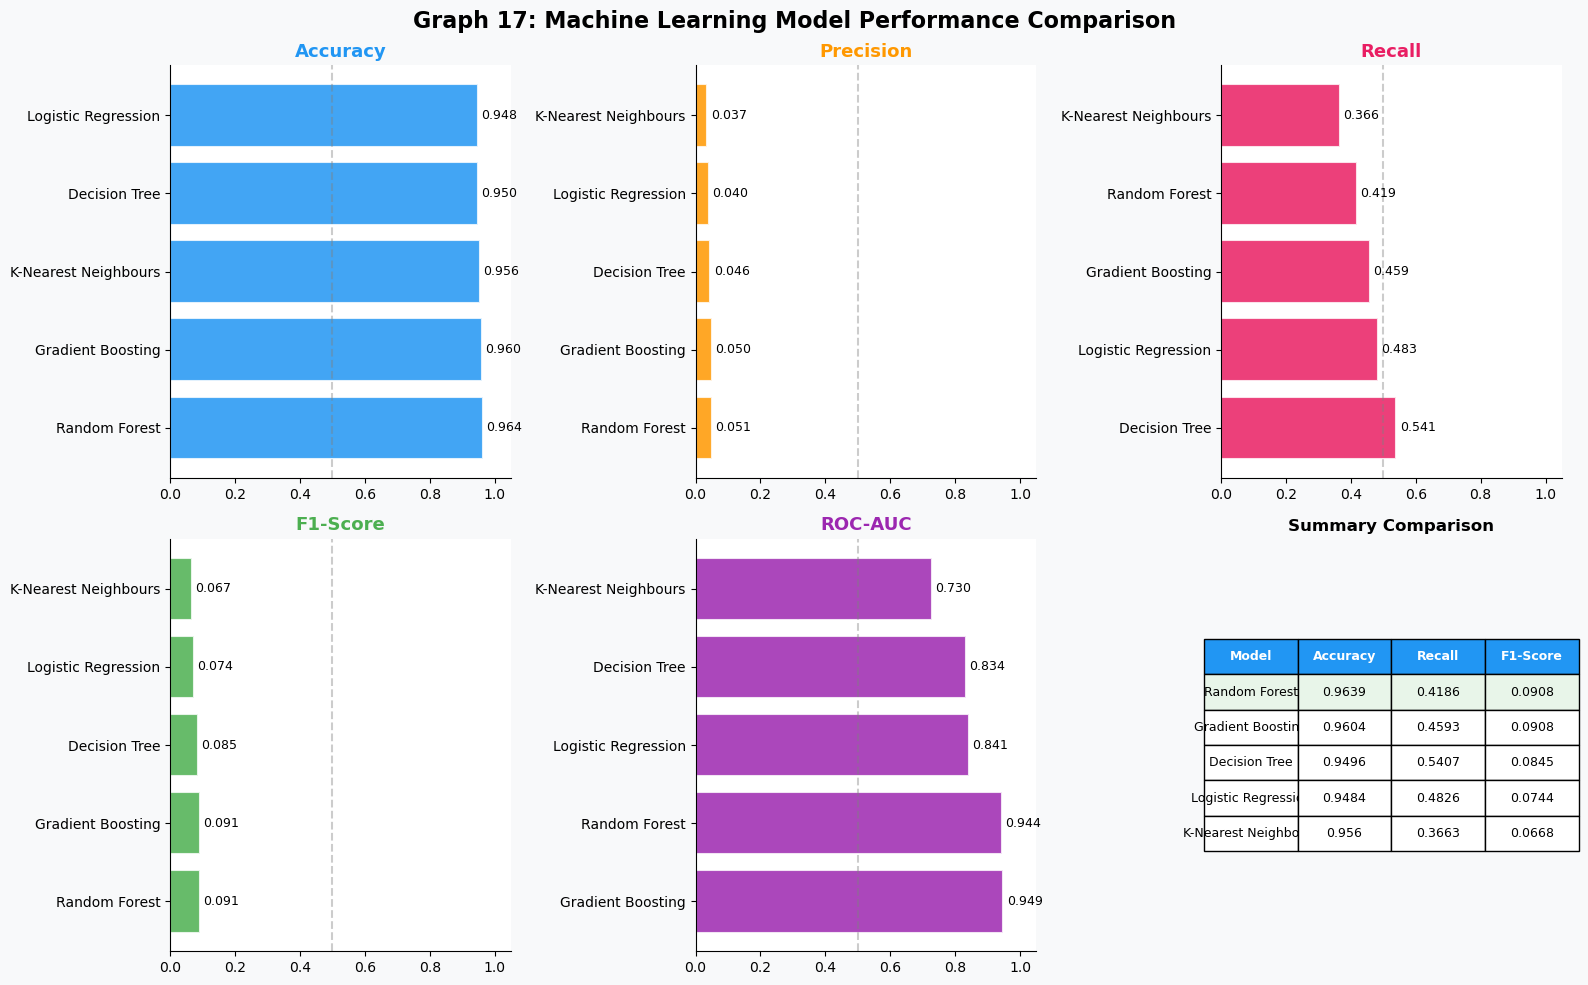

Graph 17 saved.


In [47]:
# ---------------------------------------------------------------
# GRAPH 17: Model Comparison Bar Chart
# Compare all models across all metrics side by side
# ---------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Graph 17: Machine Learning Model Performance Comparison',
             fontsize=16, fontweight='bold')
axes = axes.flatten()

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
metric_colors = ['#2196F3', '#FF9800', '#E91E63', '#4CAF50', '#9C27B0']

for i, (metric, color) in enumerate(zip(metrics, metric_colors)):
    data_sorted = results_df.sort_values(metric, ascending=False)
    bars = axes[i].barh(data_sorted['Model'], data_sorted[metric],
                        color=color, alpha=0.85, edgecolor='white', linewidth=1.5)
    axes[i].set_title(metric, fontsize=13, fontweight='bold', color=color)
    axes[i].set_xlim(0, 1.05)
    axes[i].axvline(x=0.5, color='grey', linestyle='--', alpha=0.4)
    for bar, val in zip(bars, data_sorted[metric]):
        axes[i].text(val + 0.01, bar.get_y() + bar.get_height()/2,
                     f'{val:.3f}', va='center', fontsize=9)

# Last subplot: Summary table
axes[5].axis('off')
table_data = results_df[['Model','Accuracy','Recall','F1-Score']].values
col_labels = ['Model','Accuracy','Recall','F1-Score']
tbl = axes[5].table(cellText=table_data, colLabels=col_labels,
                    loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.1, 1.8)
for key, cell in tbl.get_celld().items():
    if key[0] == 0:
        cell.set_facecolor('#2196F3')
        cell.set_text_props(color='white', fontweight='bold')
    elif key[0] == 1:  # Best model row
        cell.set_facecolor('#E8F5E9')
axes[5].set_title('Summary Comparison', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('graph17_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 17 saved.")


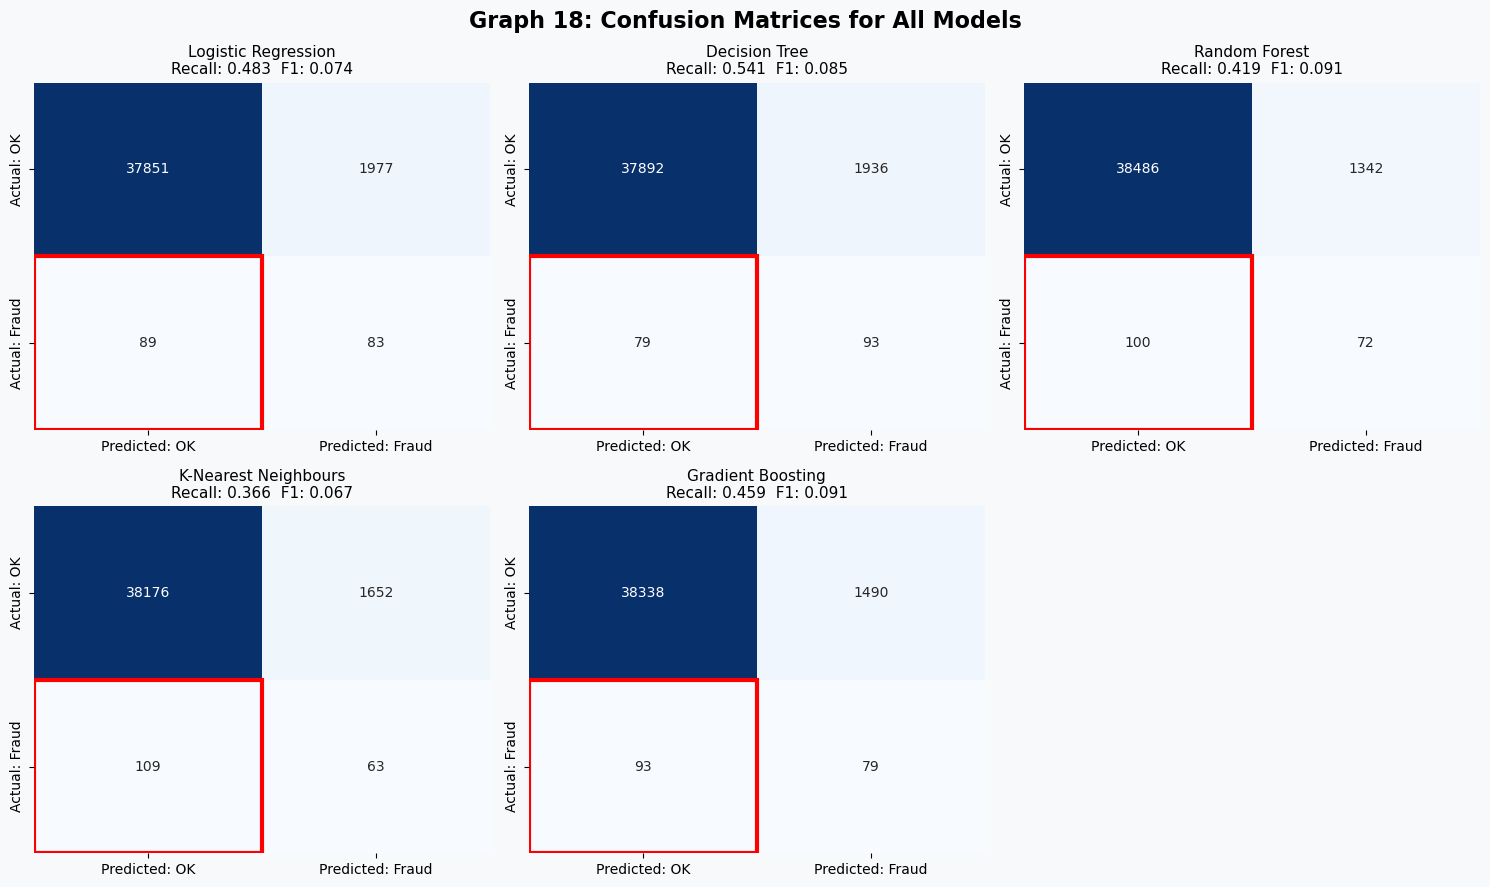

Graph 18 saved.


In [48]:
# ---------------------------------------------------------------
# GRAPH 18: Confusion Matrix Grid
# Shows how each model performs:
# True Positive (TP) = correctly caught fraud
# False Negative (FN) = missed fraud (most dangerous mistake!)
# ---------------------------------------------------------------

n_models = len(results_list)
cols = 3
rows = (n_models + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4.5*rows))
fig.suptitle('Graph 18: Confusion Matrices for All Models',
             fontsize=16, fontweight='bold')
axes = axes.flatten()

for i, result in enumerate(results_list):
    cm = result['cm']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                ax=axes[i], cbar=False,
                xticklabels=['Predicted: OK', 'Predicted: Fraud'],
                yticklabels=['Actual: OK', 'Actual: Fraud'])
    axes[i].set_title(f"{result['name']}\nRecall: {result['recall']:.3f}  F1: {result['f1']:.3f}",
                      fontsize=11)
    # Highlight missed fraud (FN) in red
    axes[i].add_patch(plt.Rectangle((0, 1), 1, 1, fill=False,
                                     edgecolor='red', lw=3, label='Missed Fraud'))

# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('graph18_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 18 saved.")


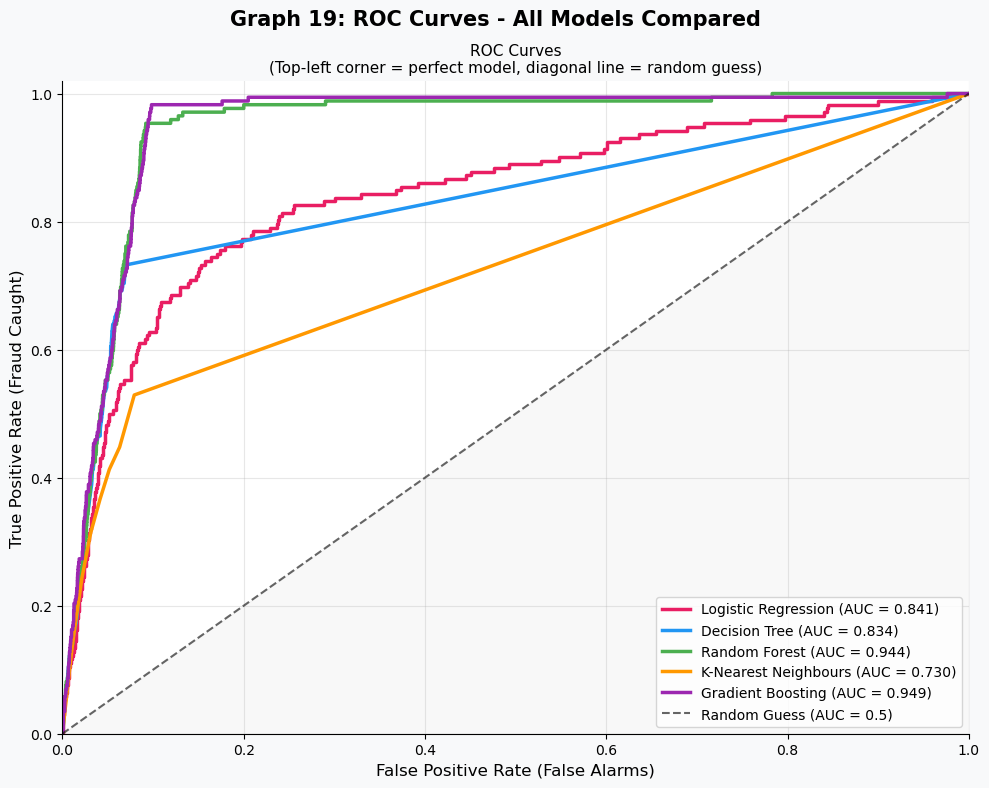

Graph 19 saved.


In [49]:
# ---------------------------------------------------------------
# GRAPH 19: ROC Curves for All Models
# ROC curve shows the tradeoff between catching fraud (TPR)
# and false alarms (FPR)
# Better model = curve closer to the top-left corner
# AUC (Area Under Curve) closer to 1.0 = better model
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))
fig.suptitle('Graph 19: ROC Curves - All Models Compared',
             fontsize=15, fontweight='bold')

# Define colours for each model's curve
roc_colors = ['#E91E63','#2196F3','#4CAF50','#FF9800','#9C27B0','#00BCD4']

for i, result in enumerate(results_list):
    if result['y_prob'] is not None:
        fpr, tpr, _ = roc_curve(y_test, result['y_prob'])
        ax.plot(fpr, tpr, linewidth=2.5,
                label=f"{result['name']} (AUC = {result['auc']:.3f})",
                color=roc_colors[i % len(roc_colors)])

# Diagonal line = random guessing
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Guess (AUC = 0.5)', alpha=0.6)

ax.set_xlabel('False Positive Rate (False Alarms)', fontsize=12)
ax.set_ylabel('True Positive Rate (Fraud Caught)', fontsize=12)
ax.set_title('ROC Curves\n(Top-left corner = perfect model, diagonal line = random guess)', fontsize=11)
ax.legend(fontsize=10, loc='lower right')
ax.fill_between([0, 1], [0, 1], alpha=0.05, color='grey')
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('graph19_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 19 saved.")


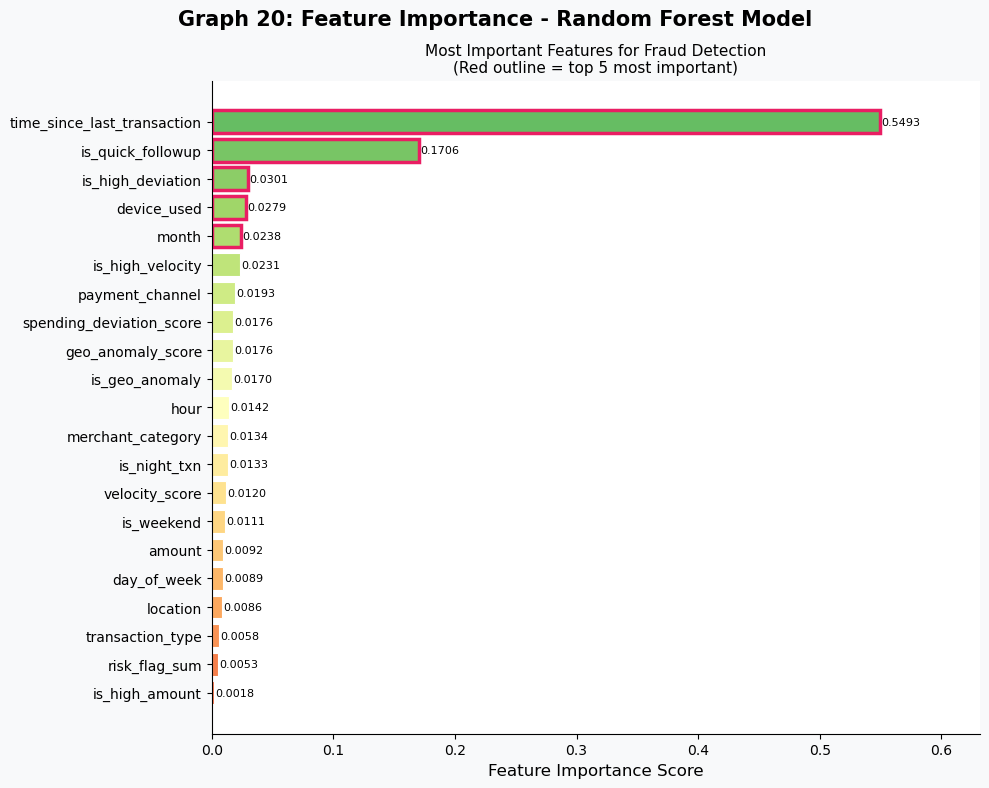

Graph 20 saved.


In [50]:
# ---------------------------------------------------------------
# GRAPH 20: Feature Importance (from Random Forest)
# Shows which features are most useful for detecting fraud
# Higher bar = more important for the model's decisions
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))
fig.suptitle('Graph 20: Feature Importance - Random Forest Model',
             fontsize=15, fontweight='bold')

# Get feature importance from the Random Forest model
rf_model = rf_result['model']
importances = pd.Series(rf_model.feature_importances_, index=feature_cols)
importances = importances.sort_values(ascending=True)

# Draw horizontal bar chart
colors_fi = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(importances)))
bars = ax.barh(importances.index, importances.values,
               color=colors_fi, edgecolor='white', linewidth=0.8)

# Colour the top 5 features differently to highlight them
top5_idx = importances.nlargest(5).index
for bar, feat in zip(bars, importances.index):
    if feat in top5_idx:
        bar.set_edgecolor('#E91E63')
        bar.set_linewidth(2.5)
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
            f'{bar.get_width():.4f}', va='center', fontsize=8)

ax.set_xlabel('Feature Importance Score', fontsize=12)
ax.set_title('Most Important Features for Fraud Detection\n'
             '(Red outline = top 5 most important)', fontsize=11)
ax.set_xlim(0, importances.max() * 1.15)

plt.tight_layout()
plt.savefig('graph20_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graph 20 saved.")


In [51]:
# ---------------------------------------------------------------
# Final summary print - show the best model and all scores
# ---------------------------------------------------------------

best = results_df.iloc[0]
print("=" * 60)
print("FINAL PROJECT SUMMARY")
print("=" * 60)
print(f"Dataset size  : {len(df):,} transactions analysed")
print(f"Fraud cases   : {df['is_fraud'].sum():,} ({df['is_fraud'].mean()*100:.2f}%)")
print(f"Features used : {len(feature_cols)} (including 7 engineered features)")
print(f"Models trained: {len(results_list)}")
print()
print("BEST MODEL RESULT:")
print(f"  Model    : {best['Model']}")
print(f"  Accuracy : {best['Accuracy']*100:.2f}%")
print(f"  Precision: {best['Precision']*100:.2f}%")
print(f"  Recall   : {best['Recall']*100:.2f}%")
print(f"  F1-Score : {best['F1-Score']*100:.2f}%")
print(f"  ROC-AUC  : {best['ROC-AUC']:.4f}")
print()
print("All graphs saved as PNG files in the current folder.")
print("=" * 60)


FINAL PROJECT SUMMARY
Dataset size  : 200,000 transactions analysed
Fraud cases   : 862 (0.43%)
Features used : 21 (including 7 engineered features)
Models trained: 5

BEST MODEL RESULT:
  Model    : Random Forest
  Accuracy : 96.39%
  Precision: 5.09%
  Recall   : 41.86%
  F1-Score : 9.08%
  ROC-AUC  : 0.9443

All graphs saved as PNG files in the current folder.
